# 6.5 — Traditional Classification Benchmark and Explainability

## Research Commons Māori-origin classification

This notebook is the **final traditional-method benchmark** for the Māori research data findability study.

It is designed to do enough traditional modelling to make the later research comparison scientifically credible **without turning the traditional-method section into the main contribution of the paper**.

The notebook covers representative traditional text-classification families:

1. **Majority-class baseline** — shows why accuracy alone is misleading under imbalance.
2. **Transparent keyword retrieval** — represents explicit lexical matching/search.
3. **TF-IDF + Logistic Regression** — linear probabilistic/discriminative classifier.
4. **TF-IDF + Linear SVM** — linear maximum-margin classifier.
5. **TF-IDF + Multinomial Naive Bayes** — classical probabilistic text classifier.

It also retains the explainability work that is most useful for the paper:

- field-aware TF-IDF;
- unigram vs added phrase features;
- class-weighting ablation where supported;
- training-only cross-validation;
- held-out evaluation;
- Māori precision, recall, macro F1 and AUPRC;
- confusion matrices;
- review-burden analysis;
- lexical cue analysis;
- exact Logistic Regression feature contributions;
- calibrated per-record Logistic Regression probability;
- disagreement overlap across traditional classifiers;
- text-defined lexical challenge groups;
- reproducible representative cases;
- bootstrap confidence intervals.

---

## What this notebook does **not** do

- It does not use embedding-model predictions.
- It does not use LLM predictions.
- It does not use generated reasons.
- It does not use generated confidence scores as model inputs.
- It does not use clustering, because this is a supervised binary classification task with an existing training target.
- It does not claim to have evaluated "every possible traditional algorithm".

The defensible claim is:

> **Representative, well-established traditional lexical classification approaches were evaluated under a common repository-metadata setting.**

The existing `classification_label` is used only as:

1. the supervised target on the training split; and
2. the comparison/reference label on the held-out test split.

All downstream metrics therefore measure **agreement with the existing generated reference labels**, not Māori-expert-validated ground truth.

## Research questions

**RQ-T1 — Explicit lexical retrieval**  
How far can transparent Māori-related keyword matching surface records relative to the reference labels?

**RQ-T2 — Learned lexical classification**  
How effectively can representative traditional classifiers learn the binary distinction from TF-IDF repository metadata?

**RQ-T3 — Representation**  
Does adding bigram/trigram information improve performance beyond a fixed unigram representation?

**RQ-T4 — Imbalance**  
For classifiers that support class weighting, how does balanced weighting change the precision–recall trade-off?

**RQ-T5 — Classifier family**  
When the lexical representation is held comparable, do Logistic Regression, Linear SVM and Multinomial Naive Bayes show materially different behaviour?

**RQ-T6 — Lexical limitation**  
Do different traditional classifiers disagree on the same kinds of records, suggesting a limitation of the lexical representation rather than only one classifier?

**RQ-T7 — Explainability**  
For the Logistic Regression reference model, which lexical features are learned globally and which exact features contribute to each paper's prediction?

**RQ-T8 — Screening trade-off**  
For the explainable Logistic Regression model, how do probability thresholds change Māori-reference recall, precision and repository review burden?

## 0. Install dependencies

In [1]:
!pip -q install datasets huggingface_hub scikit-learn pandas numpy matplotlib joblib pyarrow scipy

## 1. Imports and reproducibility

In [2]:
import os
import re
import json
import random
import warnings
import unicodedata
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from datasets import load_dataset

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_ID = "dinushiTJ/nz_research_commons_classification"
LABEL_COL = "classification_label"
ID_COL = "record_id_hash"

# Content-bearing repository metadata used by the traditional lexical models.
CONTENT_FIELDS = ["title", "subjects", "abstract"]

N_SPLITS = 5
MIN_DF = 2

# Fixed per-field unigram budgets.
UNIGRAM_MAX = {
    "title": 2500,
    "subjects": 3500,
    "abstract": 9000,
}

# Phrase blocks are ADDITIVE: they do not displace unigram features.
PHRASE_MAX = {
    "title": 1800,
    "subjects": 2800,
    "abstract": 7000,
}

LR_C = 1.0
SVM_C = 1.0
NB_ALPHA = 1.0

BOOTSTRAP_N = 1500

OUTPUT_DIR = (
    Path("/content/traditional_6_5_outputs")
    if Path("/content").exists()
    else Path("./traditional_6_5_outputs")
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_ID)
print("Content fields:", CONTENT_FIELDS)
print("Output directory:", OUTPUT_DIR.resolve())

Dataset: dinushiTJ/nz_research_commons_classification
Content fields: ['title', 'subjects', 'abstract']
Output directory: /content/traditional_6_5_outputs


## 2. Load the fixed study splits

This notebook does **not** create another train/test split.

Expected study counts:

- training: 13,271 records
  - 1,469 Māori-reference
  - 11,802 non-Māori-reference
- held-out test: 3,318 records
  - 367 Māori-reference
  - 2,951 non-Māori-reference

Model/configuration development is performed with **training-only cross-validation**.

The held-out test split is used only after the configurations have been defined.

In [3]:
dataset = load_dataset(DATASET_ID)

assert "train" in dataset and "test" in dataset
assert LABEL_COL in dataset["train"].column_names
assert LABEL_COL in dataset["test"].column_names

train_df = dataset["train"].to_pandas().copy()
test_df = dataset["test"].to_pandas().copy()

print(dataset)
print("Train:", len(train_df))
print("Test:", len(test_df))
print("Columns:", train_df.columns.tolist())

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 83.2MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/13271 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations'],
        num_rows: 13271
    })
    test: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations'],
        num_rows: 3318
    })
})
Train: 13271
Test: 3318
Columns: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations']


## 3. Decode the reference label and check the fixed split

In [4]:
label_feature = dataset["train"].features[LABEL_COL]

def decode_label(value):
    if hasattr(label_feature, "int2str") and not isinstance(value, str):
        return label_feature.int2str(int(value))

    value = str(value)
    if value in {"0", "maori_origin"}:
        return "maori_origin"
    if value in {"1", "non_maori_origin"}:
        return "non_maori_origin"
    raise ValueError(f"Unexpected label value: {value!r}")

for df in (train_df, test_df):
    df["reference_label"] = df[LABEL_COL].map(decode_label)
    # Analysis convention: Māori-origin is the positive class.
    df["y"] = (df["reference_label"] == "maori_origin").astype(int)

print("Training:")
print(train_df["reference_label"].value_counts())
print("\nHeld-out test:")
print(test_df["reference_label"].value_counts())

expected = {
    "train_total": 13271,
    "test_total": 3318,
    "train_maori": 1469,
    "train_non_maori": 11802,
    "test_maori": 367,
    "test_non_maori": 2951,
}
observed = {
    "train_total": len(train_df),
    "test_total": len(test_df),
    "train_maori": int(train_df["y"].sum()),
    "train_non_maori": int((1 - train_df["y"]).sum()),
    "test_maori": int(test_df["y"].sum()),
    "test_non_maori": int((1 - test_df["y"]).sum()),
}

for key, exp in expected.items():
    if observed[key] != exp:
        warnings.warn(
            f"{key}: expected {exp}, observed {observed[key]}. "
            "The Hugging Face dataset may have changed."
        )

if ID_COL in train_df.columns and ID_COL in test_df.columns:
    train_ids = set(train_df[ID_COL].astype(str))
    test_ids = set(test_df[ID_COL].astype(str))
    overlap = train_ids.intersection(test_ids)
    print("\nTrain/test record-ID overlap:", len(overlap))
    assert len(overlap) == 0, "Train/test record IDs overlap."

observed

Training:
reference_label
non_maori_origin    11802
maori_origin         1469
Name: count, dtype: int64

Held-out test:
reference_label
non_maori_origin    2951
maori_origin         367
Name: count, dtype: int64

Train/test record-ID overlap: 0


{'train_total': 13271,
 'test_total': 3318,
 'train_maori': 1469,
 'train_non_maori': 11802,
 'test_maori': 367,
 'test_non_maori': 2951}

## 4. Prepare field-aware content input

The traditional lexical models use:

- title;
- subjects;
- abstract.

These are kept as **separate TF-IDF fields**.

This prevents n-grams from crossing metadata-field boundaries and allows later explanations such as:

- `title → Māori education`
- `subjects → kaupapa māori`
- `abstract → whānau`

Author names and publication year are intentionally excluded from the primary lexical model to reduce author-identity and temporal shortcuts.

In [5]:
def clean_value(value):
    if value is None:
        return ""
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return " ; ".join(str(x) for x in value if x is not None)
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    return str(value)

for df in (train_df, test_df):
    for field in CONTENT_FIELDS:
        if field not in df.columns:
            warnings.warn(f"Missing field {field!r}; replacing with empty text.")
            df[field] = ""
        df[f"{field}_text"] = df[field].map(clean_value).fillna("").astype(str)

MODEL_COLUMNS = [f"{field}_text" for field in CONTENT_FIELDS]

X_train_df = train_df[MODEL_COLUMNS].copy()
X_test_df = test_df[MODEL_COLUMNS].copy()
y_train = train_df["y"].to_numpy(dtype=int)
y_test = test_df["y"].to_numpy(dtype=int)

display(X_train_df.head(3))

,title_text,subjects_text,abstract_text
0,The Te Aroha hot springs (mainly in the ninete...,,"Unique amongst New Zealand mining districts, t..."
1,Jespersen cycles on Malekula,diachrony,In the indigenous languages of Malekula Island...
2,"Fabric, fitness, and femininity: A new materi...",Activewear,Activewear refers to casual clothing designed ...


# Part A — Simple baselines

## 5. Majority-class baseline

Because the corpus is strongly imbalanced, accuracy by itself can look high even when a classifier never surfaces a Māori-reference record.

The majority baseline makes that problem explicit.

In [6]:
majority = DummyClassifier(strategy="most_frequent")
majority.fit(np.zeros((len(y_train), 1)), y_train)
majority_test_pred = majority.predict(np.zeros((len(y_test), 1)))

## 6. Frozen lexical diagnostic vocabularies

These vocabularies are **diagnostic lexical probes**, not a hand-written replacement for the reference-label definition.

Three groups are separated:

1. relatively specific Māori phrases;
2. general Māori lexical cues;
3. broader contextual vocabulary.

Broad academic words such as `research` are not used.  
`Waikato` is not treated as a Māori-positive trigger because it is also the institution/repository name.

In [7]:
SPECIFIC_MAORI_PHRASES = [
    "te reo maori",
    "kaupapa maori",
    "matauranga maori",
    "tino rangatiratanga",
    "te tiriti o waitangi",
    "treaty of waitangi",
    "waitangi tribunal",
    "treaty settlement",
    "maori data sovereignty",
    "maori health",
    "maori education",
    "maori land",
    "maori language",
    "maori culture",
    "maori identity",
    "maori knowledge",
    "maori methodology",
    "mana whenua",
    "tangata whenua",
    "mahinga kai",
]

GENERAL_MAORI_CUES = [
    "maori",
    "whanau",
    "hapu",
    "iwi",
    "marae",
    "tikanga",
    "whakapapa",
    "matauranga",
    "kaitiakitanga",
    "taonga",
    "whenua",
    "rohe",
    "urupa",
    "rangatiratanga",
]

BROAD_CONTEXT_CUES = [
    "aotearoa",
    "new zealand",
    "indigenous",
    "pacific",
    "community",
    "health",
    "education",
    "environment",
    "colonisation",
    "colonization",
]

def normalize_for_rules(text):
    text = clean_value(text).casefold()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = re.sub(r"[^a-z0-9\s'-]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def contains_term(normalized_text, term):
    term = normalize_for_rules(term)
    pattern = r"(?<!\w)" + re.escape(term).replace(r"\ ", r"\s+") + r"(?!\w)"
    return re.search(pattern, normalized_text) is not None

def combined_content(row):
    return " \\n ".join(
        clean_value(row.get(f"{field}_text", ""))
        for field in CONTENT_FIELDS
    )

def lexical_probe(row):
    text = normalize_for_rules(combined_content(row))

    specific = [t for t in SPECIFIC_MAORI_PHRASES if contains_term(text, t)]
    general = [t for t in GENERAL_MAORI_CUES if contains_term(text, t)]
    broad = [t for t in BROAD_CONTEXT_CUES if contains_term(text, t)]

    return {
        "specific_hits": list(dict.fromkeys(specific)),
        "general_hits": list(dict.fromkeys(general)),
        "broad_hits": list(dict.fromkeys(broad)),
        "has_specific": bool(specific),
        "has_general": bool(general),
        "has_broad": bool(broad),
    }

for df in (train_df, test_df):
    probe = df.apply(lexical_probe, axis=1)

    df["specific_hits"] = probe.map(
        lambda d: json.dumps(d["specific_hits"], ensure_ascii=False)
    )
    df["general_maori_hits"] = probe.map(
        lambda d: json.dumps(d["general_hits"], ensure_ascii=False)
    )
    df["broad_context_hits"] = probe.map(
        lambda d: json.dumps(d["broad_hits"], ensure_ascii=False)
    )

    df["has_specific_maori_phrase"] = probe.map(lambda d: d["has_specific"])
    df["has_general_maori_cue"] = probe.map(lambda d: d["has_general"])
    df["has_broad_context_cue"] = probe.map(lambda d: d["has_broad"])

print("Training lexical probe counts:")
display(pd.DataFrame({
    "specific_phrase_present": [int(train_df["has_specific_maori_phrase"].sum())],
    "general_maori_cue_present": [int(train_df["has_general_maori_cue"].sum())],
    "broad_context_present": [int(train_df["has_broad_context_cue"].sum())],
}))

Training lexical probe counts:


,specific_phrase_present,general_maori_cue_present,broad_context_present
0,566,1368,6761


## 7. Two transparent keyword retrieval baselines

**Strict keyword retrieval**

A record is surfaced only if at least one relatively specific Māori phrase is present.

**Inclusive keyword retrieval**

A record is surfaced if either a specific phrase or a general Māori lexical cue is present.

These are deterministic retrieval baselines. They do not produce an invented numerical confidence score.

In [8]:
for df in (train_df, test_df):
    df["keyword_strict_pred"] = df["has_specific_maori_phrase"].astype(int)
    df["keyword_inclusive_pred"] = (
        df["has_specific_maori_phrase"] | df["has_general_maori_cue"]
    ).astype(int)

## 8. Common evaluation helpers

In [9]:
def metric_row(name, y_true, y_pred, score=None, family=None, representation=None, weighting=None):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "model": name,
        "family": family,
        "representation": representation,
        "weighting": weighting,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "maori_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "auprc": np.nan if score is None else average_precision_score(y_true, score),
        "predicted_maori": int(y_pred.sum()),
        "tp": int(tp),
        "fn": int(fn),
        "fp": int(fp),
        "tn": int(tn),
    }

def show_confusion(y_true, y_pred, title, save_name=None):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])

    fig, ax = plt.subplots(figsize=(5.4, 4.4))
    ax.imshow(cm)
    ax.set_xticks([0, 1], labels=["Māori-origin", "Non-Māori-origin"])
    ax.set_yticks([0, 1], labels=["Māori-origin", "Non-Māori-origin"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Reference")
    ax.set_title(title)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center")

    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=200, bbox_inches="tight")
    plt.show()

    return cm

## 9. Training-only lexical cue prevalence audit

Before interpreting a word as a useful Māori lexical signal, examine how often it occurs in each training reference class.

This helps distinguish:

- highly class-specific lexical cues;
- terms that occur substantially in both classes;
- broad contextual vocabulary.

In [10]:
all_probe_terms = (
    [("specific", t) for t in SPECIFIC_MAORI_PHRASES]
    + [("general", t) for t in GENERAL_MAORI_CUES]
    + [("broad", t) for t in BROAD_CONTEXT_CUES]
)

normalized_training_text = train_df.apply(
    lambda row: normalize_for_rules(combined_content(row)),
    axis=1,
)

probe_rows = []

for category, term in all_probe_terms:
    hits = normalized_training_text.map(lambda text: contains_term(text, term))
    pos = train_df["y"].eq(1)
    neg = train_df["y"].eq(0)

    probe_rows.append({
        "category": category,
        "term": term,
        "train_docs_total": int(hits.sum()),
        "train_maori_docs": int((hits & pos).sum()),
        "train_non_maori_docs": int((hits & neg).sum()),
        "train_maori_prevalence": float(hits[pos].mean()),
        "train_non_maori_prevalence": float(hits[neg].mean()),
        "prevalence_difference": float(hits[pos].mean() - hits[neg].mean()),
    })

lexical_prevalence_df = pd.DataFrame(probe_rows).sort_values(
    ["category", "train_maori_prevalence"],
    ascending=[True, False],
)

display(lexical_prevalence_df.round(4))
lexical_prevalence_df.to_csv(
    OUTPUT_DIR / "training_lexical_probe_prevalence.csv",
    index=False,
)

,category,term,train_docs_total,train_maori_docs,train_non_maori_docs,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference
35,broad,new zealand,4380,762,3618,0.5187,0.3066,0.2122
36,broad,indigenous,652,429,223,0.2920,0.0189,0.2731
34,broad,aotearoa,812,394,418,0.2682,0.0354,0.2328
40,broad,education,1512,246,1266,0.1675,0.1073,0.0602
39,broad,health,970,231,739,0.1572,0.0626,0.0946
38,broad,community,1201,223,978,0.1518,0.0829,0.0689
41,broad,environment,1143,130,1013,0.0885,0.0858,0.0027
42,broad,colonisation,128,87,41,0.0592,0.0035,0.0557
37,broad,pacific,357,69,288,0.0470,0.0244,0.0226
43,broad,colonization,44,13,31,0.0088,0.0026,0.0062


# Part B — Common field-aware TF-IDF representation

## 10. Representation definitions

Two representations are benchmarked:

### Unigram
Field-specific unigrams only.

### Unigram + phrases
The **same unigram blocks**, plus separate bigram/trigram blocks.

This design matters because phrases do not compete with unigrams for the same feature budget.

The purpose is to test whether added local phrase information changes performance while preserving the unigram representation.

In [11]:
def make_tfidf(ngram_range, max_features):
    return TfidfVectorizer(
        lowercase=True,
        min_df=MIN_DF,
        max_features=max_features,
        ngram_range=ngram_range,
        norm="l2",
        token_pattern=r"(?u)\b\w\w+\b",
    )

def make_feature_transformer(representation):
    transformers = []

    # Fixed unigram blocks
    for field in CONTENT_FIELDS:
        transformers.append((
            f"{field}_uni",
            make_tfidf((1, 1), UNIGRAM_MAX[field]),
            f"{field}_text",
        ))

    # Additive phrase blocks
    if representation == "unigram_plus_phrases":
        for field in CONTENT_FIELDS:
            transformers.append((
                f"{field}_phrase",
                make_tfidf((2, 3), PHRASE_MAX[field]),
                f"{field}_text",
            ))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=True,
    )

# Part C — Representative traditional classifiers

## 11. Model families and configurations

The benchmark is intentionally representative rather than exhaustive.

### Logistic Regression
Linear discriminative classifier.  
Run unweighted and `class_weight="balanced"`.

### Linear SVM
Linear maximum-margin classifier.  
Run unweighted and `class_weight="balanced"`.

### Multinomial Naive Bayes
Classical probabilistic text classifier.  
No synthetic class-weight variant is added because `MultinomialNB` does not implement the same `class_weight` mechanism.

Each family is run with:

- unigrams;
- unigrams + added bigram/trigram features.

This creates a compact but defensible traditional benchmark.

In [12]:
def make_lr(class_weight=None):
    return LogisticRegression(
        C=LR_C,
        solver="liblinear",
        max_iter=3000,
        class_weight=class_weight,
        random_state=SEED,
    )

def make_svm(class_weight=None):
    return LinearSVC(
        C=SVM_C,
        class_weight=class_weight,
        random_state=SEED,
    )

def make_nb():
    return MultinomialNB(alpha=NB_ALPHA)

MODEL_CONFIGS = {}

for representation in ["unigram", "unigram_plus_phrases"]:
    MODEL_CONFIGS[f"lr__{representation}__unweighted"] = {
        "family": "Logistic Regression",
        "representation": representation,
        "weighting": "unweighted",
        "estimator_factory": lambda: make_lr(None),
    }
    MODEL_CONFIGS[f"lr__{representation}__balanced"] = {
        "family": "Logistic Regression",
        "representation": representation,
        "weighting": "balanced",
        "estimator_factory": lambda: make_lr("balanced"),
    }

    MODEL_CONFIGS[f"svm__{representation}__unweighted"] = {
        "family": "Linear SVM",
        "representation": representation,
        "weighting": "unweighted",
        "estimator_factory": lambda: make_svm(None),
    }
    MODEL_CONFIGS[f"svm__{representation}__balanced"] = {
        "family": "Linear SVM",
        "representation": representation,
        "weighting": "balanced",
        "estimator_factory": lambda: make_svm("balanced"),
    }

    MODEL_CONFIGS[f"mnb__{representation}__standard"] = {
        "family": "Multinomial Naive Bayes",
        "representation": representation,
        "weighting": "standard",
        "estimator_factory": make_nb,
    }

print("Number of traditional TF-IDF configurations:", len(MODEL_CONFIGS))
for name, cfg in MODEL_CONFIGS.items():
    print(name, "->", cfg["family"], cfg["representation"], cfg["weighting"])

Number of traditional TF-IDF configurations: 10
lr__unigram__unweighted -> Logistic Regression unigram unweighted
lr__unigram__balanced -> Logistic Regression unigram balanced
svm__unigram__unweighted -> Linear SVM unigram unweighted
svm__unigram__balanced -> Linear SVM unigram balanced
mnb__unigram__standard -> Multinomial Naive Bayes unigram standard
lr__unigram_plus_phrases__unweighted -> Logistic Regression unigram_plus_phrases unweighted
lr__unigram_plus_phrases__balanced -> Logistic Regression unigram_plus_phrases balanced
svm__unigram_plus_phrases__unweighted -> Linear SVM unigram_plus_phrases unweighted
svm__unigram_plus_phrases__balanced -> Linear SVM unigram_plus_phrases balanced
mnb__unigram_plus_phrases__standard -> Multinomial Naive Bayes unigram_plus_phrases standard


## 12. Exact class weights used by the balanced linear models

In [13]:
n = len(y_train)
n_pos = int(y_train.sum())
n_neg = int((1 - y_train).sum())

balanced_weight_maori = n / (2 * n_pos)
balanced_weight_non_maori = n / (2 * n_neg)

print({
    "maori_origin": balanced_weight_maori,
    "non_maori_origin": balanced_weight_non_maori,
})

{'maori_origin': 4.517018379850239, 'non_maori_origin': 0.5622352143704457}


# Part D — Training-only cross-validation benchmark

## 13. Five-fold out-of-fold evaluation

All traditional TF-IDF configurations are evaluated using exactly the same 5 stratified folds.

For each record, the out-of-fold prediction is made by a model that did not train on that record.

For AUPRC:

- Logistic Regression → positive-class probability;
- Multinomial Naive Bayes → positive-class probability;
- Linear SVM → decision-function score.

AUPRC accepts a continuous ranking score and does not require that all model families expose probabilities.

In [14]:
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

def make_pipeline_from_config(cfg):
    return Pipeline([
        ("features", make_feature_transformer(cfg["representation"])),
        ("classifier", cfg["estimator_factory"]()),
    ])

def continuous_score(fitted_pipeline, X):
    clf = fitted_pipeline.named_steps["classifier"]

    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X)[:, 1]

    if hasattr(clf, "decision_function"):
        score = fitted_pipeline.decision_function(X)
        return np.asarray(score, dtype=float)

    raise TypeError("Classifier exposes neither predict_proba nor decision_function.")

cv_store = {}
cv_fold_rows = []

for config_name, cfg in MODEL_CONFIGS.items():
    print(f"\n=== {config_name} ===")

    oof_pred = np.zeros(len(y_train), dtype=int)
    oof_score = np.zeros(len(y_train), dtype=float)
    oof_fold = np.full(len(y_train), -1, dtype=int)

    for fold, (tr_idx, va_idx) in enumerate(
        skf.split(X_train_df, y_train),
        start=1,
    ):
        pipe = make_pipeline_from_config(cfg)
        pipe.fit(X_train_df.iloc[tr_idx], y_train[tr_idx])

        pred = pipe.predict(X_train_df.iloc[va_idx])
        score = continuous_score(pipe, X_train_df.iloc[va_idx])

        oof_pred[va_idx] = pred
        oof_score[va_idx] = score
        oof_fold[va_idx] = fold

        fold_row = metric_row(
            name=f"{config_name}_fold_{fold}",
            y_true=y_train[va_idx],
            y_pred=pred,
            score=score,
            family=cfg["family"],
            representation=cfg["representation"],
            weighting=cfg["weighting"],
        )
        fold_row["config"] = config_name
        fold_row["fold"] = fold
        cv_fold_rows.append(fold_row)

    assert np.all(oof_fold > 0)

    cv_store[config_name] = {
        "pred": oof_pred,
        "score": oof_score,
        "fold": oof_fold,
    }

cv_fold_metrics_df = pd.DataFrame(cv_fold_rows)
cv_fold_metrics_df.to_csv(
    OUTPUT_DIR / "cv_fold_metrics_all_traditional_configs.csv",
    index=False,
)

display(
    cv_fold_metrics_df.groupby(
        ["family", "representation", "weighting"]
    )[
        [
            "accuracy",
            "macro_f1",
            "maori_precision",
            "maori_recall",
            "maori_f1",
            "auprc",
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
)


=== lr__unigram__unweighted ===

=== lr__unigram__balanced ===

=== svm__unigram__unweighted ===

=== svm__unigram__balanced ===

=== mnb__unigram__standard ===

=== lr__unigram_plus_phrases__unweighted ===

=== lr__unigram_plus_phrases__balanced ===

=== svm__unigram_plus_phrases__unweighted ===

=== svm__unigram_plus_phrases__balanced ===

=== mnb__unigram_plus_phrases__standard ===


accuracy          \
                                                            mean     std   
family                  representation       weighting                     
Linear SVM              unigram              balanced     0.9694  0.0021   
                                             unweighted   0.9700  0.0021   
                        unigram_plus_phrases balanced     0.9709  0.0009   
                                             unweighted   0.9703  0.0017   
Logistic Regression     unigram              balanced     0.9681  0.0032   
                                             unweighted   0.9632  0.0013   
                        unigram_plus_phrases balanced     0.9687  0.0030   
                                             unweighted   0.9630  0.0015   
Multinomial Naive Bayes unigram              standard     0.9575  0.0022   
                        unigram_plus_phrases standard     0.9566  0.0044   

                                                        macro_f1          \
                                                            mean     std   
family                  representation       weighting                     
Linear SVM              unigram              balanced     0.9181  0.0056   
                                             unweighted   0.9166  0.0060   
                        unigram_plus_phrases balanced     0.9204  0.0028   
                                             unweighted   0.9168  0.0049   
Logistic Regression     unigram              balanced     0.9165  0.0083   
                                             unweighted   0.8913  0.0042   
                        unigram_plus_phrases balanced     0.9168  0.0078   
                                             unweighted   0.8909  0.0047   
Multinomial Naive Bayes unigram              standard     0.8771  0.0066   
                        unigram_plus_phrases standard     0.8862  0.0097   

                                                        maori_precision  \
                                                                   mean   
family                  representation       weighting                    
Linear SVM              unigram              balanced            0.9092   
                                             unweighted          0.9528   
                        unigram_plus_phrases balanced            0.9400   
                                             unweighted          0.9631   
Logistic Regression     unigram              balanced            0.8802   
                                             unweighted          0.9843   
                        unigram_plus_phrases balanced            0.8983   
                                             unweighted          0.9823   
Multinomial Naive Bayes unigram              standard            0.9233   
                        unigram_plus_phrases standard            0.8292   

                                                                maori_recall  \
                                                            std         mean   
family                  representation       weighting                         
Linear SVM              unigram              balanced    0.0109       0.8039   
                                             unweighted  0.0125       0.7672   
                        unigram_plus_phrases balanced    0.0102       0.7876   
                                             unweighted  0.0128       0.7611   
Logistic Regression     unigram              balanced    0.0198       0.8237   
                                             unweighted  0.0107       0.6780   
                        unigram_plus_phrases balanced    0.0223       0.8087   
                                             unweighted  0.0089       0.6780   
Multinomial Naive Bayes unigram              standard    0.0133       0.6719   
                        unigram_plus_phrases standard    0.0345       0.7672   

                                                             

## 14. Compact out-of-fold comparison table

In [15]:
cv_summary_rows = []

for config_name, cfg in MODEL_CONFIGS.items():
    obj = cv_store[config_name]

    row = metric_row(
        name=config_name,
        y_true=y_train,
        y_pred=obj["pred"],
        score=obj["score"],
        family=cfg["family"],
        representation=cfg["representation"],
        weighting=cfg["weighting"],
    )

    family_fold = cv_fold_metrics_df[
        cv_fold_metrics_df["config"] == config_name
    ]

    row["cv_macro_f1_mean"] = family_fold["macro_f1"].mean()
    row["cv_macro_f1_std"] = family_fold["macro_f1"].std()
    row["cv_auprc_mean"] = family_fold["auprc"].mean()
    row["cv_auprc_std"] = family_fold["auprc"].std()
    row["cv_maori_recall_mean"] = family_fold["maori_recall"].mean()
    row["cv_maori_precision_mean"] = family_fold["maori_precision"].mean()

    cv_summary_rows.append(row)

cv_summary_df = (
    pd.DataFrame(cv_summary_rows)
    .sort_values(
        ["cv_macro_f1_mean", "cv_auprc_mean"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(cv_summary_df.round(4))
cv_summary_df.to_csv(
    OUTPUT_DIR / "cv_summary_all_traditional_configs.csv",
    index=False,
)

,model,family,representation,weighting,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,...,tp,fn,fp,tn,cv_macro_f1_mean,cv_macro_f1_std,cv_auprc_mean,cv_auprc_std,cv_maori_recall_mean,cv_maori_precision_mean
0,svm__unigram_plus_phrases__balanced,Linear SVM,unigram_plus_phrases,balanced,0.9709,0.9204,0.9399,0.7876,0.8570,0.9167,...,1157,312,74,11728,0.9204,0.0028,0.9171,0.0078,0.7876,0.9400
1,svm__unigram__balanced,Linear SVM,unigram,balanced,0.9694,0.9181,0.9092,0.8039,0.8533,0.9143,...,1181,288,118,11684,0.9181,0.0056,0.9147,0.0088,0.8039,0.9092
2,svm__unigram_plus_phrases__unweighted,Linear SVM,unigram_plus_phrases,unweighted,0.9703,0.9169,0.9630,0.7611,0.8502,0.9200,...,1118,351,43,11759,0.9168,0.0049,0.9203,0.0083,0.7611,0.9631
3,lr__unigram_plus_phrases__balanced,Logistic Regression,unigram_plus_phrases,balanced,0.9687,0.9167,0.8980,0.8087,0.8510,0.9195,...,1188,281,135,11667,0.9168,0.0078,0.9199,0.0121,0.8087,0.8983
4,svm__unigram__unweighted,Linear SVM,unigram,unweighted,0.9700,0.9166,0.9527,0.7672,0.8499,0.9194,...,1127,342,56,11746,0.9166,0.0060,0.9197,0.0105,0.7672,0.9528
5,lr__unigram__balanced,Logistic Regression,unigram,balanced,0.9681,0.9165,0.8800,0.8237,0.8509,0.9194,...,1210,259,165,11637,0.9165,0.0083,0.9194,0.0104,0.8237,0.8802
6,lr__unigram__unweighted,Logistic Regression,unigram,unweighted,0.9632,0.8913,0.9842,0.6780,0.8029,0.9213,...,996,473,16,11786,0.8913,0.0042,0.9212,0.0117,0.6780,0.9843
7,lr__unigram_plus_phrases__unweighted,Logistic Regression,unigram_plus_phrases,unweighted,0.9630,0.8909,0.9822,0.6780,0.8023,0.9207,...,996,473,18,11784,0.8909,0.0047,0.9209,0.0129,0.6780,0.9823
8,mnb__unigram_plus_phrases__standard,Multinomial Naive Bayes,unigram_plus_phrases,standard,0.9566,0.8861,0.8281,0.7672,0.7965,0.8661,...,1127,342,234,11568,0.8862,0.0097,0.8667,0.0112,0.7672,0.8292
9,mnb__unigram__standard,Multinomial Naive Bayes,unigram,standard,0.9575,0.8771,0.9233,0.6719,0.7778,0.8599,...,987,482,82,11720,0.8771,0.0066,0.8604,0.0070,0.6719,0.9233


## 15. Training-only representation and weighting effect tables

These tables answer two focused questions without using the test set:

1. Does adding phrases help within a classifier/weighting setting?
2. Does balanced class weighting help within a fixed representation?

The purpose is interpretation, not endless hyperparameter tuning.

In [16]:
def cv_mean(config_name, metric):
    return float(
        cv_fold_metrics_df.loc[
            cv_fold_metrics_df["config"] == config_name,
            metric,
        ].mean()
    )

effect_rows = []

# Phrase effects
for prefix, family, weighting in [
    ("lr", "Logistic Regression", "unweighted"),
    ("lr", "Logistic Regression", "balanced"),
    ("svm", "Linear SVM", "unweighted"),
    ("svm", "Linear SVM", "balanced"),
    ("mnb", "Multinomial Naive Bayes", "standard"),
]:
    base = f"{prefix}__unigram__{weighting}"
    phrase = f"{prefix}__unigram_plus_phrases__{weighting}"

    for metric in ["macro_f1", "maori_recall", "maori_precision", "auprc"]:
        effect_rows.append({
            "effect": "add_phrases",
            "family": family,
            "weighting": weighting,
            "metric": metric,
            "baseline_cv_mean": cv_mean(base, metric),
            "changed_cv_mean": cv_mean(phrase, metric),
            "difference": cv_mean(phrase, metric) - cv_mean(base, metric),
        })

# Weighting effects
for prefix, family in [
    ("lr", "Logistic Regression"),
    ("svm", "Linear SVM"),
]:
    for representation in ["unigram", "unigram_plus_phrases"]:
        base = f"{prefix}__{representation}__unweighted"
        changed = f"{prefix}__{representation}__balanced"

        for metric in ["macro_f1", "maori_recall", "maori_precision", "auprc"]:
            effect_rows.append({
                "effect": "balanced_class_weight",
                "family": family,
                "weighting": representation,
                "metric": metric,
                "baseline_cv_mean": cv_mean(base, metric),
                "changed_cv_mean": cv_mean(changed, metric),
                "difference": cv_mean(changed, metric) - cv_mean(base, metric),
            })

cv_effects_df = pd.DataFrame(effect_rows)
display(cv_effects_df.round(4))
cv_effects_df.to_csv(
    OUTPUT_DIR / "cv_representation_and_weighting_effects.csv",
    index=False,
)

,effect,family,weighting,metric,baseline_cv_mean,changed_cv_mean,difference
0,add_phrases,Logistic Regression,unweighted,macro_f1,0.8913,0.8909,-0.0004
1,add_phrases,Logistic Regression,unweighted,maori_recall,0.6780,0.6780,0.0000
2,add_phrases,Logistic Regression,unweighted,maori_precision,0.9843,0.9823,-0.0020
3,add_phrases,Logistic Regression,unweighted,auprc,0.9212,0.9209,-0.0002
4,add_phrases,Logistic Regression,balanced,macro_f1,0.9165,0.9168,0.0002
5,add_phrases,Logistic Regression,balanced,maori_recall,0.8237,0.8087,-0.0150
6,add_phrases,Logistic Regression,balanced,maori_precision,0.8802,0.8983,0.0181
7,add_phrases,Logistic Regression,balanced,auprc,0.9194,0.9199,0.0005
8,add_phrases,Linear SVM,unweighted,macro_f1,0.9166,0.9168,0.0002
9,add_phrases,Linear SVM,unweighted,maori_recall,0.7672,0.7611,-0.0061


## 16. Choose one configuration per traditional classifier family using training CV only

For the compact family-level held-out comparison, one configuration is selected **within each classifier family**.

Selection rule:

1. highest mean cross-validated macro F1;
2. if within 0.002 macro F1, prefer higher mean AUPRC;
3. if still effectively tied, prefer the simpler representation;
4. if still tied for a linear model, prefer the unweighted model.

This does not remove the full configuration table. It simply provides a compact representative result for each family.

In [17]:
def complexity_key(row):
    representation_complexity = 1 if row["representation"] == "unigram_plus_phrases" else 0
    weighting_complexity = 1 if row["weighting"] == "balanced" else 0
    return (representation_complexity, weighting_complexity)

selected_family_configs = {}

for family, g in cv_summary_df.groupby("family"):
    g = g.copy()

    best_macro = g["cv_macro_f1_mean"].max()
    near_macro = g[g["cv_macro_f1_mean"] >= best_macro - 0.002].copy()

    best_ap = near_macro["cv_auprc_mean"].max()
    near_ap = near_macro[near_macro["cv_auprc_mean"] >= best_ap - 0.002].copy()

    chosen_idx = sorted(
        near_ap.index.tolist(),
        key=lambda idx: complexity_key(near_ap.loc[idx]),
    )[0]

    selected_family_configs[family] = near_ap.loc[chosen_idx, "model"]

print("Training-CV-selected configuration per family:")
for family, config_name in selected_family_configs.items():
    print(f"{family}: {config_name}")

with open(
    OUTPUT_DIR / "selected_family_configs.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(selected_family_configs, f, indent=2, ensure_ascii=False)

Training-CV-selected configuration per family:
Linear SVM: svm__unigram_plus_phrases__balanced
Logistic Regression: lr__unigram__balanced
Multinomial Naive Bayes: mnb__unigram_plus_phrases__standard


## 17. Select the Logistic Regression explainability reference model

Detailed probabilities and exact feature explanations are focused on Logistic Regression because:

- it is linear and directly interpretable;
- its coefficient contributions can be reconstructed exactly;
- it exposes a natural decision score and probability;
- it avoids turning the traditional benchmark into several separate interpretability studies.

The explainability model is the Logistic Regression configuration selected by the same training-only rule above.

In [18]:
EXPLAIN_LR_CONFIG = selected_family_configs["Logistic Regression"]
print("Logistic Regression explainability reference:", EXPLAIN_LR_CONFIG)

selected_lr_oof = cv_store[EXPLAIN_LR_CONFIG]

Logistic Regression explainability reference: lr__unigram__balanced


## 18. Save all out-of-fold predictions

In [19]:
oof_frames = []

for config_name, cfg in MODEL_CONFIGS.items():
    obj = cv_store[config_name]

    tmp = pd.DataFrame({
        ID_COL: (
            train_df[ID_COL].astype(str).to_numpy()
            if ID_COL in train_df.columns
            else np.arange(len(train_df)).astype(str)
        ),
        "reference_label": train_df["reference_label"].to_numpy(),
        "y": y_train,
        "config": config_name,
        "family": cfg["family"],
        "representation": cfg["representation"],
        "weighting": cfg["weighting"],
        "fold": obj["fold"],
        "oof_prediction": np.where(
            obj["pred"] == 1,
            "maori_origin",
            "non_maori_origin",
        ),
        "oof_score": obj["score"],
    })

    oof_frames.append(tmp)

oof_predictions_df = pd.concat(oof_frames, ignore_index=True)
oof_predictions_df.to_csv(
    OUTPUT_DIR / "training_oof_predictions_all_traditional_configs.csv",
    index=False,
)

print("Saved OOF predictions.")

Saved OOF predictions.


# Part E — Logistic Regression probability and screening analysis

## 19. Fit a training-only sigmoid calibrator to out-of-fold LR decision scores

The calibration model is learned only from out-of-fold training decisions.

Then the final Logistic Regression model is fitted on all training records.

For a held-out paper, the chain is:

**repository metadata → TF-IDF → final LR decision score → calibrated probability**

The calibrated value is still a probability of agreement with the existing reference-label target, not a culturally authoritative probability that a paper "is Māori research".

In [20]:
# The OOF score for LR is probability because the generic benchmark score helper
# uses predict_proba where available. For calibration we specifically need the LR
# decision function, so regenerate OOF LR decision scores on the same folds.

lr_cfg = MODEL_CONFIGS[EXPLAIN_LR_CONFIG]

lr_oof_decision = np.zeros(len(y_train), dtype=float)
lr_oof_pred = np.zeros(len(y_train), dtype=int)

for fold, (tr_idx, va_idx) in enumerate(
    skf.split(X_train_df, y_train),
    start=1,
):
    pipe = make_pipeline_from_config(lr_cfg)
    pipe.fit(X_train_df.iloc[tr_idx], y_train[tr_idx])

    lr_oof_decision[va_idx] = pipe.decision_function(
        X_train_df.iloc[va_idx]
    )
    lr_oof_pred[va_idx] = pipe.predict(
        X_train_df.iloc[va_idx]
    )

platt_calibrator = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=3000,
    random_state=SEED,
)
platt_calibrator.fit(
    lr_oof_decision.reshape(-1, 1),
    y_train,
)

final_lr_pipeline = make_pipeline_from_config(lr_cfg)
final_lr_pipeline.fit(X_train_df, y_train)

print("Final explainability LR fitted.")

Final explainability LR fitted.


## 20. Training-only LR threshold versus review burden

No arbitrary `low / medium / high confidence` bins are invented.

Instead, the out-of-fold LR scores are transformed into calibrated probabilities and evaluated over explicit thresholds.

,threshold,maori_recall,maori_precision,macro_f1,records_surfaced,reference_maori_surfaced,reference_maori_missed,additional_records_for_review
0,0.050,0.9408,0.5188,0.8038,2664,1382,87,1282
1,0.075,0.9278,0.6060,0.8449,2249,1363,106,886
2,0.100,0.9074,0.6570,0.8630,2029,1333,136,696
3,0.125,0.8938,0.6999,0.8770,1876,1313,156,563
4,0.150,0.8822,0.7351,0.8873,1763,1296,173,467
5,0.175,0.8761,0.7656,0.8963,1681,1287,182,394
6,0.200,0.8639,0.7862,0.9000,1614,1269,200,345
7,0.225,0.8598,0.8117,0.9069,1556,1263,206,293
8,0.250,0.8523,0.8280,0.9099,1512,1252,217,260
9,0.275,0.8414,0.8443,0.9116,1464,1236,233,228


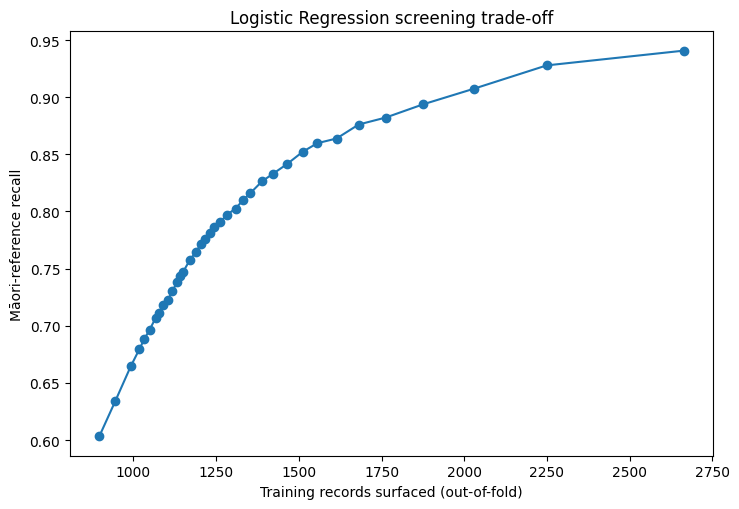

In [21]:
lr_oof_p_cal = platt_calibrator.predict_proba(
    lr_oof_decision.reshape(-1, 1)
)[:, 1]

thresholds = np.round(np.arange(0.05, 0.951, 0.025), 3)

training_threshold_rows = []

for threshold in thresholds:
    pred = (lr_oof_p_cal >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        pred,
        labels=[0, 1],
    ).ravel()

    training_threshold_rows.append({
        "threshold": threshold,
        "maori_recall": recall_score(y_train, pred, zero_division=0),
        "maori_precision": precision_score(y_train, pred, zero_division=0),
        "macro_f1": f1_score(y_train, pred, average="macro", zero_division=0),
        "records_surfaced": int(pred.sum()),
        "reference_maori_surfaced": int(tp),
        "reference_maori_missed": int(fn),
        "additional_records_for_review": int(fp),
    })

training_threshold_df = pd.DataFrame(training_threshold_rows)
display(training_threshold_df.round(4))

training_threshold_df.to_csv(
    OUTPUT_DIR / "training_oof_lr_threshold_review_burden.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.plot(
    training_threshold_df["records_surfaced"],
    training_threshold_df["maori_recall"],
    marker="o",
)
ax.set_xlabel("Training records surfaced (out-of-fold)")
ax.set_ylabel("Māori-reference recall")
ax.set_title("Logistic Regression screening trade-off")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "training_oof_lr_review_burden.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Part F — Frozen held-out benchmark

## 21. Fit every predefined traditional configuration on all training records

This is **not** test-set model selection.

The configuration set was already fixed and evaluated with training-only CV.

The held-out evaluation now provides the final descriptive benchmark.

In [22]:
fitted_models = {}
heldout_predictions = {}
heldout_scores = {}
heldout_rows = []

# Majority baseline
heldout_rows.append(
    metric_row(
        "majority_non_maori",
        y_test,
        majority_test_pred,
        score=None,
        family="Majority baseline",
        representation="none",
        weighting="none",
    )
)

# Keyword baselines
heldout_rows.append(
    metric_row(
        "keyword_strict",
        y_test,
        test_df["keyword_strict_pred"].to_numpy(),
        score=None,
        family="Keyword retrieval",
        representation="specific phrases",
        weighting="none",
    )
)
heldout_rows.append(
    metric_row(
        "keyword_inclusive",
        y_test,
        test_df["keyword_inclusive_pred"].to_numpy(),
        score=None,
        family="Keyword retrieval",
        representation="specific + general Māori cues",
        weighting="none",
    )
)

# TF-IDF classifier configurations
for config_name, cfg in MODEL_CONFIGS.items():
    print("Fitting:", config_name)

    pipe = make_pipeline_from_config(cfg)
    pipe.fit(X_train_df, y_train)

    pred = pipe.predict(X_test_df)
    score = continuous_score(pipe, X_test_df)

    fitted_models[config_name] = pipe
    heldout_predictions[config_name] = pred
    heldout_scores[config_name] = score

    heldout_rows.append(
        metric_row(
            name=config_name,
            y_true=y_test,
            y_pred=pred,
            score=score,
            family=cfg["family"],
            representation=cfg["representation"],
            weighting=cfg["weighting"],
        )
    )

heldout_all_configs_df = pd.DataFrame(heldout_rows)

display(
    heldout_all_configs_df.sort_values(
        ["macro_f1", "auprc"],
        ascending=False,
        na_position="last",
    ).round(4)
)

heldout_all_configs_df.to_csv(
    OUTPUT_DIR / "heldout_all_traditional_configs.csv",
    index=False,
)

Fitting: lr__unigram__unweighted
Fitting: lr__unigram__balanced
Fitting: svm__unigram__unweighted
Fitting: svm__unigram__balanced
Fitting: mnb__unigram__standard
Fitting: lr__unigram_plus_phrases__unweighted
Fitting: lr__unigram_plus_phrases__balanced
Fitting: svm__unigram_plus_phrases__unweighted
Fitting: svm__unigram_plus_phrases__balanced
Fitting: mnb__unigram_plus_phrases__standard


,model,family,representation,weighting,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn
2,keyword_inclusive,Keyword retrieval,specific + general Māori cues,none,0.9741,0.9322,0.9096,0.8501,0.8789,NaN,343,312,55,31,2920
5,svm__unigram__unweighted,Linear SVM,unigram,unweighted,0.9714,0.9208,0.9533,0.7793,0.8576,0.9220,300,286,81,14,2937
6,svm__unigram__balanced,Linear SVM,unigram,balanced,0.9675,0.9142,0.8843,0.8120,0.8466,0.9178,337,298,69,39,2912
4,lr__unigram__balanced,Logistic Regression,unigram,balanced,0.9659,0.9129,0.8508,0.8392,0.8450,0.9202,362,308,59,54,2897
11,svm__unigram_plus_phrases__balanced,Linear SVM,unigram_plus_phrases,balanced,0.9675,0.9120,0.9085,0.7847,0.8421,0.9078,317,288,79,29,2922
10,svm__unigram_plus_phrases__unweighted,Linear SVM,unigram_plus_phrases,unweighted,0.9675,0.9099,0.9331,0.7602,0.8378,0.9104,299,279,88,20,2931
9,lr__unigram_plus_phrases__balanced,Logistic Regression,unigram_plus_phrases,balanced,0.9635,0.9047,0.8576,0.8038,0.8298,0.9111,344,295,72,49,2902
7,mnb__unigram__standard,Multinomial Naive Bayes,unigram,standard,0.9587,0.8820,0.9167,0.6894,0.7869,0.8602,276,253,114,23,2928
12,mnb__unigram_plus_phrases__standard,Multinomial Naive Bayes,unigram_plus_phrases,standard,0.9548,0.8817,0.8163,0.7629,0.7887,0.8538,343,280,87,63,2888
8,lr__unigram_plus_phrases__unweighted,Logistic Regression,unigram_plus_phrases,unweighted,0.9581,0.8754,0.9597,0.6485,0.7740,0.9119,248,238,129,10,2941


## 22. Compact held-out comparison: representative family results

This is the table most likely to be useful in the paper.

It includes:

- majority baseline;
- strict keyword baseline;
- inclusive keyword baseline;
- one training-CV-selected Logistic Regression configuration;
- one training-CV-selected Linear SVM configuration;
- one training-CV-selected Multinomial Naive Bayes configuration.

In [23]:
compact_names = [
    "majority_non_maori",
    "keyword_strict",
    "keyword_inclusive",
    selected_family_configs["Logistic Regression"],
    selected_family_configs["Linear SVM"],
    selected_family_configs["Multinomial Naive Bayes"],
]

compact_heldout_df = (
    heldout_all_configs_df[
        heldout_all_configs_df["model"].isin(compact_names)
    ]
    .copy()
)

order = {name: i for i, name in enumerate(compact_names)}
compact_heldout_df["_order"] = compact_heldout_df["model"].map(order)
compact_heldout_df = (
    compact_heldout_df
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

display(compact_heldout_df.round(4))
compact_heldout_df.to_csv(
    OUTPUT_DIR / "heldout_compact_traditional_family_comparison.csv",
    index=False,
)

,model,family,representation,weighting,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn
0,majority_non_maori,Majority baseline,none,none,0.8894,0.4707,0.0000,0.0000,0.0000,NaN,0,0,367,0,2951
1,keyword_strict,Keyword retrieval,specific phrases,none,0.9277,0.7423,0.9635,0.3597,0.5238,NaN,137,132,235,5,2946
2,keyword_inclusive,Keyword retrieval,specific + general Māori cues,none,0.9741,0.9322,0.9096,0.8501,0.8789,NaN,343,312,55,31,2920
3,lr__unigram__balanced,Logistic Regression,unigram,balanced,0.9659,0.9129,0.8508,0.8392,0.8450,0.9202,362,308,59,54,2897
4,svm__unigram_plus_phrases__balanced,Linear SVM,unigram_plus_phrases,balanced,0.9675,0.9120,0.9085,0.7847,0.8421,0.9078,317,288,79,29,2922
5,mnb__unigram_plus_phrases__standard,Multinomial Naive Bayes,unigram_plus_phrases,standard,0.9548,0.8817,0.8163,0.7629,0.7887,0.8538,343,280,87,63,2888


## 23. Comparison figure

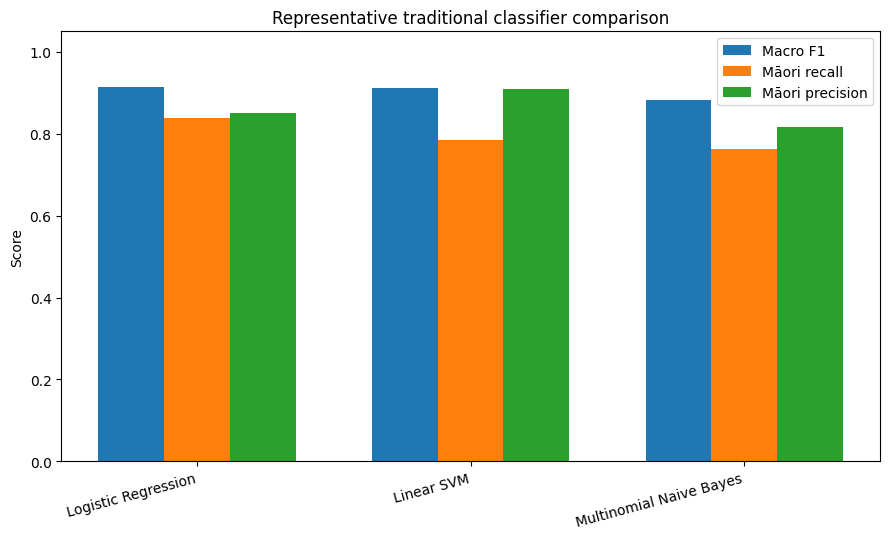

In [24]:
plot_df = compact_heldout_df[
    compact_heldout_df["family"].isin(
        ["Logistic Regression", "Linear SVM", "Multinomial Naive Bayes"]
    )
].copy()

x = np.arange(len(plot_df))
width = 0.24

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(x - width, plot_df["macro_f1"], width, label="Macro F1")
ax.bar(x, plot_df["maori_recall"], width, label="Māori recall")
ax.bar(x + width, plot_df["maori_precision"], width, label="Māori precision")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["family"], rotation=15, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Representative traditional classifier comparison")
ax.legend()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "traditional_classifier_family_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## 24. Confusion matrices for the three selected classifier families

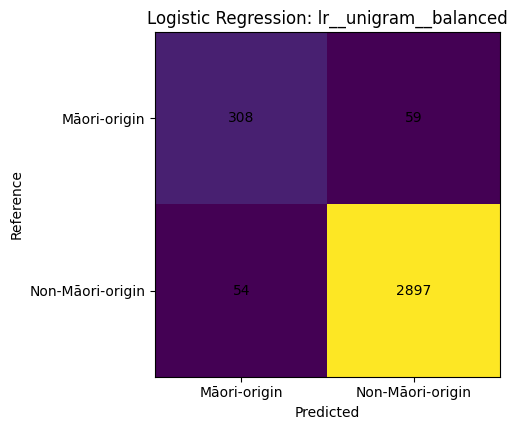

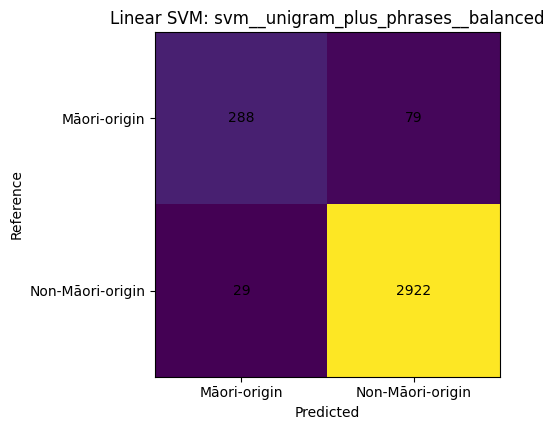

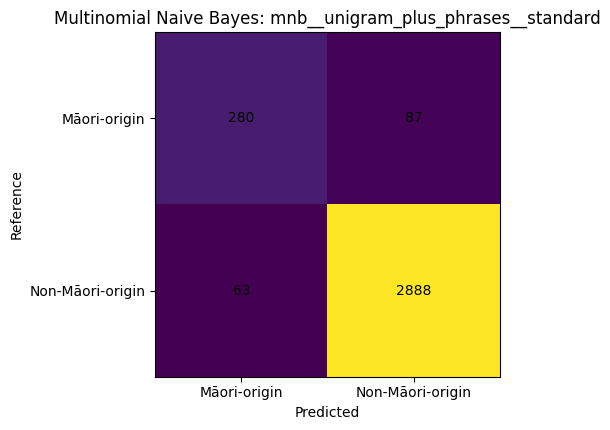

In [25]:
for family in [
    "Logistic Regression",
    "Linear SVM",
    "Multinomial Naive Bayes",
]:
    config_name = selected_family_configs[family]
    pred = heldout_predictions[config_name]

    safe = family.lower().replace(" ", "_")
    show_confusion(
        y_test,
        pred,
        f"{family}: {config_name}",
        f"confusion_{safe}.png",
    )

# Part G — Are the traditional classifiers failing on the same records?

## 25. Per-record family predictions

A key research question is whether different classifier families make errors on the same records.

If Logistic Regression, Linear SVM and Naive Bayes repeatedly struggle on the same papers despite different classification rules, that is stronger evidence that the difficulty lies in the **lexical representation / available metadata signal**, rather than only one particular classifier.

In [26]:
selected_lr_name = selected_family_configs["Logistic Regression"]
selected_svm_name = selected_family_configs["Linear SVM"]
selected_nb_name = selected_family_configs["Multinomial Naive Bayes"]

selected_lr_pred = heldout_predictions[selected_lr_name]
selected_svm_pred = heldout_predictions[selected_svm_name]
selected_nb_pred = heldout_predictions[selected_nb_name]

selected_lr_score = heldout_scores[selected_lr_name]
selected_svm_score = heldout_scores[selected_svm_name]
selected_nb_score = heldout_scores[selected_nb_name]

family_prediction_df = pd.DataFrame({
    ID_COL: (
        test_df[ID_COL].astype(str).to_numpy()
        if ID_COL in test_df.columns
        else np.arange(len(test_df)).astype(str)
    ),
    "reference_label": test_df["reference_label"].to_numpy(),
    "lr_prediction": np.where(selected_lr_pred == 1, "maori_origin", "non_maori_origin"),
    "svm_prediction": np.where(selected_svm_pred == 1, "maori_origin", "non_maori_origin"),
    "mnb_prediction": np.where(selected_nb_pred == 1, "maori_origin", "non_maori_origin"),
    "lr_agreement": selected_lr_pred == y_test,
    "svm_agreement": selected_svm_pred == y_test,
    "mnb_agreement": selected_nb_pred == y_test,
    "lr_score": selected_lr_score,
    "svm_score": selected_svm_score,
    "mnb_score": selected_nb_score,
})

family_prediction_df["n_traditional_classifiers_disagreeing"] = (
    (~family_prediction_df["lr_agreement"]).astype(int)
    + (~family_prediction_df["svm_agreement"]).astype(int)
    + (~family_prediction_df["mnb_agreement"]).astype(int)
)

display(
    family_prediction_df["n_traditional_classifiers_disagreeing"]
    .value_counts()
    .sort_index()
    .rename_axis("number_disagreeing")
    .to_frame("records")
)

,records
number_disagreeing,
0,3118
1,92
2,45
3,63


## 26. Error-overlap pattern table

In [27]:
def agreement_pattern(row):
    states = []
    for name in ["lr", "svm", "mnb"]:
        states.append(
            f"{name}_{'agree' if row[f'{name}_agreement'] else 'disagree'}"
        )
    return " | ".join(states)

family_prediction_df["agreement_pattern"] = family_prediction_df.apply(
    agreement_pattern,
    axis=1,
)

error_pattern_df = (
    family_prediction_df["agreement_pattern"]
    .value_counts()
    .rename_axis("agreement_pattern")
    .reset_index(name="records")
)

display(error_pattern_df)
error_pattern_df.to_csv(
    OUTPUT_DIR / "traditional_classifier_error_overlap_patterns.csv",
    index=False,
)

,agreement_pattern,records
0,lr_agree | svm_agree | mnb_agree,3118
1,lr_disagree | svm_disagree | mnb_disagree,63
2,lr_agree | svm_agree | mnb_disagree,57
3,lr_disagree | svm_agree | mnb_agree,20
4,lr_disagree | svm_agree | mnb_disagree,15
5,lr_disagree | svm_disagree | mnb_agree,15
6,lr_agree | svm_disagree | mnb_agree,15
7,lr_agree | svm_disagree | mnb_disagree,15


## 27. Pairwise disagreement-overlap statistics

In [28]:
error_masks = {
    "Logistic Regression": ~family_prediction_df["lr_agreement"].to_numpy(),
    "Linear SVM": ~family_prediction_df["svm_agreement"].to_numpy(),
    "Multinomial Naive Bayes": ~family_prediction_df["mnb_agreement"].to_numpy(),
}

overlap_rows = []

families = list(error_masks)
for i, a in enumerate(families):
    for b in families[i + 1:]:
        ea = error_masks[a]
        eb = error_masks[b]

        intersection = int(np.logical_and(ea, eb).sum())
        union = int(np.logical_or(ea, eb).sum())
        jaccard = intersection / union if union else np.nan

        overlap_rows.append({
            "model_a": a,
            "model_b": b,
            "errors_a": int(ea.sum()),
            "errors_b": int(eb.sum()),
            "shared_errors": intersection,
            "error_union": union,
            "jaccard_error_overlap": jaccard,
        })

error_overlap_df = pd.DataFrame(overlap_rows)
display(error_overlap_df.round(4))
error_overlap_df.to_csv(
    OUTPUT_DIR / "traditional_pairwise_error_overlap.csv",
    index=False,
)

,model_a,model_b,errors_a,errors_b,shared_errors,error_union,jaccard_error_overlap
0,Logistic Regression,Linear SVM,113,108,78,143,0.5455
1,Logistic Regression,Multinomial Naive Bayes,113,150,78,185,0.4216
2,Linear SVM,Multinomial Naive Bayes,108,150,78,180,0.4333


# Part H — Text-defined lexical challenge groups

## 28. Define lexical conditions without using the reference label

Every test record is assigned to exactly one text-defined group:

1. `specific_maori_phrase_present`
2. `general_maori_cue_only`
3. `broad_context_only`
4. `no_selected_lexical_signal`

The reference label is deliberately not used to construct these groups.

In [29]:
def lexical_condition(row):
    if row["has_specific_maori_phrase"]:
        return "specific_maori_phrase_present"
    if row["has_general_maori_cue"]:
        return "general_maori_cue_only"
    if row["has_broad_context_cue"]:
        return "broad_context_only"
    return "no_selected_lexical_signal"

test_df["lexical_condition"] = test_df.apply(
    lexical_condition,
    axis=1,
)

display(
    test_df["lexical_condition"]
    .value_counts()
    .rename_axis("lexical_condition")
    .to_frame("records")
)

,records
lexical_condition,
no_selected_lexical_signal,1558
broad_context_only,1417
general_maori_cue_only,206
specific_maori_phrase_present,137


## 29. Compare selected traditional classifier families within each lexical condition

In [30]:
condition_model_rows = []

selected_models_for_conditions = {
    "Logistic Regression": selected_lr_pred,
    "Linear SVM": selected_svm_pred,
    "Multinomial Naive Bayes": selected_nb_pred,
}

for condition, indices in test_df.groupby("lexical_condition").groups.items():
    idx = np.asarray(list(indices), dtype=int)
    y_group = y_test[idx]

    for family, all_pred in selected_models_for_conditions.items():
        pred_group = all_pred[idx]

        row = {
            "lexical_condition": condition,
            "family": family,
            "n": len(idx),
            "reference_maori_n": int(y_group.sum()),
            "reference_non_maori_n": int((1 - y_group).sum()),
            "agreement_rate": float((pred_group == y_group).mean()),
            "predicted_maori_rate": float(pred_group.mean()),
            "maori_recall": recall_score(
                y_group,
                pred_group,
                zero_division=0,
            ),
            "maori_precision": precision_score(
                y_group,
                pred_group,
                zero_division=0,
            ),
        }
        condition_model_rows.append(row)

lexical_condition_model_df = pd.DataFrame(condition_model_rows)

display(lexical_condition_model_df.round(4))
lexical_condition_model_df.to_csv(
    OUTPUT_DIR / "lexical_condition_by_traditional_classifier.csv",
    index=False,
)

,lexical_condition,family,n,reference_maori_n,reference_non_maori_n,agreement_rate,predicted_maori_rate,maori_recall,maori_precision
0,broad_context_only,Logistic Regression,1417,38,1379,0.9598,0.0430,0.5526,0.3443
1,broad_context_only,Linear SVM,1417,38,1379,0.9704,0.0282,0.4737,0.4500
2,broad_context_only,Multinomial Naive Bayes,1417,38,1379,0.9499,0.0473,0.4474,0.2537
3,general_maori_cue_only,Logistic Regression,206,180,26,0.8252,0.7864,0.8500,0.9444
4,general_maori_cue_only,Linear SVM,206,180,26,0.7816,0.7039,0.7778,0.9655
5,general_maori_cue_only,Multinomial Naive Bayes,206,180,26,0.7427,0.6942,0.7500,0.9441
6,no_selected_lexical_signal,Logistic Regression,1558,17,1541,0.9917,0.0077,0.4706,0.6667
7,no_selected_lexical_signal,Linear SVM,1558,17,1541,0.9923,0.0045,0.3529,0.8571
8,no_selected_lexical_signal,Multinomial Naive Bayes,1558,17,1541,0.9910,0.0071,0.4118,0.6364
9,specific_maori_phrase_present,Logistic Regression,137,132,5,0.9489,0.9270,0.9545,0.9921


## 30. Reference-label distribution inside each text-defined lexical condition

In [31]:
condition_reference_table = pd.crosstab(
    test_df["lexical_condition"],
    test_df["reference_label"],
    margins=True,
)

display(condition_reference_table)
condition_reference_table.to_csv(
    OUTPUT_DIR / "lexical_condition_reference_distribution.csv"
)

reference_label,maori_origin,non_maori_origin,All
lexical_condition,,,
broad_context_only,38,1379,1417
general_maori_cue_only,180,26,206
no_selected_lexical_signal,17,1541,1558
specific_maori_phrase_present,132,5,137
All,367,2951,3318


# Part I — Detailed Logistic Regression explainability

## 31. Final LR prediction and calibrated probability

Only Logistic Regression receives the detailed per-paper explanation because it is the transparent reference classifier for this stage.

The other traditional classifiers remain important benchmark comparators.

In [32]:
# Re-use the already fitted benchmark model corresponding to the selected LR configuration.
# Refit final_lr_pipeline was done earlier using the identical configuration.

lr_test_pred = final_lr_pipeline.predict(X_test_df)
lr_test_decision = final_lr_pipeline.decision_function(X_test_df)
lr_test_p_raw = final_lr_pipeline.predict_proba(X_test_df)[:, 1]
lr_test_p_cal = platt_calibrator.predict_proba(
    lr_test_decision.reshape(-1, 1)
)[:, 1]

# Sanity check against the benchmark copy.
assert np.array_equal(lr_test_pred, selected_lr_pred)

## 32. Calibration diagnostics for the explainable LR

,score,brier,ece_10
0,raw_lr_probability,0.03053,0.05890
1,oof_sigmoid_calibrated_probability,0.02525,0.00718


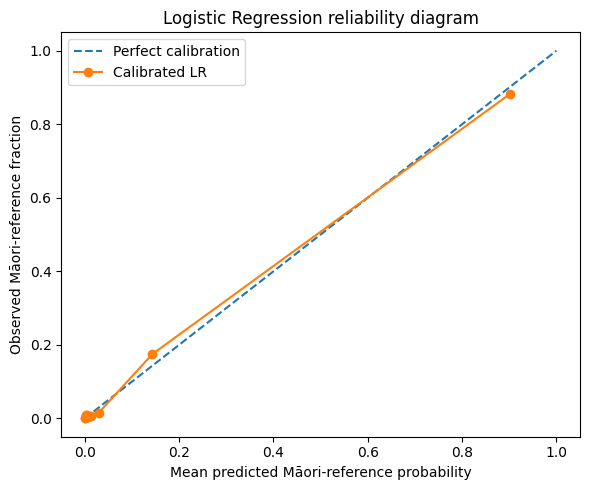

In [33]:
def expected_calibration_error(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)

    bins = np.linspace(0, 1, n_bins + 1)
    ids = np.digitize(probs, bins[1:-1], right=False)

    ece = 0.0
    rows = []

    for b in range(n_bins):
        mask = ids == b
        if not mask.any():
            continue

        mean_p = float(probs[mask].mean())
        observed = float(y_true[mask].mean())
        weight = float(mask.mean())

        ece += weight * abs(mean_p - observed)

        rows.append({
            "bin": b,
            "n": int(mask.sum()),
            "mean_predicted_probability": mean_p,
            "observed_maori_reference_fraction": observed,
            "weight": weight,
        })

    return ece, pd.DataFrame(rows)

brier_raw = brier_score_loss(y_test, lr_test_p_raw)
brier_cal = brier_score_loss(y_test, lr_test_p_cal)

ece_raw, ece_raw_df = expected_calibration_error(y_test, lr_test_p_raw)
ece_cal, ece_cal_df = expected_calibration_error(y_test, lr_test_p_cal)

lr_calibration_summary_df = pd.DataFrame([
    {
        "score": "raw_lr_probability",
        "brier": brier_raw,
        "ece_10": ece_raw,
    },
    {
        "score": "oof_sigmoid_calibrated_probability",
        "brier": brier_cal,
        "ece_10": ece_cal,
    },
])

display(lr_calibration_summary_df.round(5))
lr_calibration_summary_df.to_csv(
    OUTPUT_DIR / "lr_calibration_summary.csv",
    index=False,
)

prob_true, prob_pred = calibration_curve(
    y_test,
    lr_test_p_cal,
    n_bins=10,
    strategy="quantile",
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.plot(prob_pred, prob_true, marker="o", label="Calibrated LR")
ax.set_xlabel("Mean predicted Māori-reference probability")
ax.set_ylabel("Observed Māori-reference fraction")
ax.set_title("Logistic Regression reliability diagram")
ax.legend()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "lr_reliability_diagram.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## 33. Held-out LR threshold versus repository review burden

In [34]:
heldout_threshold_rows = []

for threshold in thresholds:
    pred = (lr_test_p_cal >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1],
    ).ravel()

    heldout_threshold_rows.append({
        "threshold": threshold,
        "maori_recall": recall_score(y_test, pred, zero_division=0),
        "maori_precision": precision_score(y_test, pred, zero_division=0),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "records_surfaced": int(pred.sum()),
        "reference_maori_surfaced": int(tp),
        "reference_maori_missed": int(fn),
        "additional_records_for_review": int(fp),
    })

heldout_lr_threshold_df = pd.DataFrame(heldout_threshold_rows)
display(heldout_lr_threshold_df.round(4))

heldout_lr_threshold_df.to_csv(
    OUTPUT_DIR / "heldout_lr_threshold_review_burden.csv",
    index=False,
)

,threshold,maori_recall,maori_precision,macro_f1,records_surfaced,reference_maori_surfaced,reference_maori_missed,additional_records_for_review
0,0.050,0.9564,0.5400,0.8171,650,351,16,299
1,0.075,0.9373,0.6347,0.8591,542,344,23,198
2,0.100,0.9237,0.6862,0.8779,494,339,28,155
3,0.125,0.9019,0.7323,0.8907,452,331,36,121
4,0.150,0.8910,0.7605,0.8980,430,327,40,103
5,0.175,0.8856,0.7775,0.9025,418,325,42,93
6,0.200,0.8801,0.7956,0.9070,406,323,44,83
7,0.225,0.8774,0.8010,0.9081,402,322,45,80
8,0.250,0.8774,0.8131,0.9119,396,322,45,74
9,0.275,0.8692,0.8179,0.9113,390,319,48,71


## 34. Extract field-specific Logistic Regression coefficients

Because the analysis convention is:

- `1 = maori_origin`
- `0 = non_maori_origin`

then:

- positive coefficient → pushes toward Māori-origin;
- negative coefficient → pushes toward non-Māori-origin.

These are learned associations with the reference labels. They are not definitions of Māori research.

In [35]:
lr_feature_transformer = final_lr_pipeline.named_steps["features"]
lr_classifier = final_lr_pipeline.named_steps["classifier"]

X_train_lr = lr_feature_transformer.transform(X_train_df)
X_test_lr = lr_feature_transformer.transform(X_test_df)

if not sparse.issparse(X_train_lr):
    X_train_lr = sparse.csr_matrix(X_train_lr)
if not sparse.issparse(X_test_lr):
    X_test_lr = sparse.csr_matrix(X_test_lr)

feature_names = lr_feature_transformer.get_feature_names_out()
coefficients = lr_classifier.coef_[0]
intercept = float(lr_classifier.intercept_[0])

assert len(feature_names) == len(coefficients)

def parse_feature_metadata(feature_name):
    block, token = feature_name.split("__", 1)

    if block.endswith("_uni"):
        field = block[:-4]
        block_type = "unigram"
    elif block.endswith("_phrase"):
        field = block[:-7]
        block_type = "phrase"
    else:
        field = block
        block_type = "unknown"

    return field, block_type, token, len(token.split())

parsed_features = [
    parse_feature_metadata(name)
    for name in feature_names
]

pos_mask = y_train == 1
neg_mask = y_train == 0

df_pos = np.asarray(
    X_train_lr[pos_mask].getnnz(axis=0)
).ravel()
df_neg = np.asarray(
    X_train_lr[neg_mask].getnnz(axis=0)
).ravel()

lr_global_features_df = pd.DataFrame({
    "full_feature_name": feature_names,
    "field": [x[0] for x in parsed_features],
    "feature_block": [x[1] for x in parsed_features],
    "feature": [x[2] for x in parsed_features],
    "ngram_n": [x[3] for x in parsed_features],
    "coefficient": coefficients,
    "direction": np.where(
        coefficients > 0,
        "toward_maori",
        "toward_non_maori",
    ),
    "train_doc_frequency": df_pos + df_neg,
    "train_maori_doc_frequency": df_pos,
    "train_non_maori_doc_frequency": df_neg,
    "train_maori_prevalence": df_pos / pos_mask.sum(),
    "train_non_maori_prevalence": df_neg / neg_mask.sum(),
})

lr_global_features_df[
    "prevalence_difference_maori_minus_non"
] = (
    lr_global_features_df["train_maori_prevalence"]
    - lr_global_features_df["train_non_maori_prevalence"]
)

top_maori_features_df = lr_global_features_df.nlargest(
    40,
    "coefficient",
)
top_non_maori_features_df = lr_global_features_df.nsmallest(
    40,
    "coefficient",
)

print("Top Māori-direction lexical features")
display(top_maori_features_df.head(30).round(4))

print("Top non-Māori-direction lexical features")
display(top_non_maori_features_df.head(30).round(4))

lr_global_features_df.to_csv(
    OUTPUT_DIR / "lr_all_feature_coefficients.csv",
    index=False,
)
top_maori_features_df.to_csv(
    OUTPUT_DIR / "lr_top_40_maori_direction_features.csv",
    index=False,
)
top_non_maori_features_df.to_csv(
    OUTPUT_DIR / "lr_top_40_non_maori_direction_features.csv",
    index=False,
)

Top Māori-direction lexical features


,full_feature_name,field,feature_block,feature,ngram_n,coefficient,direction,train_doc_frequency,train_maori_doc_frequency,train_non_maori_doc_frequency,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference_maori_minus_non
9907,abstract_uni__māori,abstract,unigram,māori,1,14.0897,toward_maori,927,870,57,0.5922,0.0048,0.5874
9477,abstract_uni__maori,abstract,unigram,maori,1,8.5028,toward_maori,294,264,30,0.1797,0.0025,0.1772
1467,title_uni__māori,title,unigram,māori,1,7.2115,toward_maori,405,405,0,0.2757,0.0000,0.2757
12571,abstract_uni__te,abstract,unigram,te,1,6.5118,toward_maori,736,519,217,0.3533,0.0184,0.3349
8683,abstract_uni__indigenous,abstract,unigram,indigenous,1,6.3452,toward_maori,625,409,216,0.2784,0.0183,0.2601
1340,title_uni__maori,title,unigram,maori,1,5.5413,toward_maori,154,154,0,0.1048,0.0000,0.1048
5152,abstract_uni__aotearoa,abstract,unigram,aotearoa,1,4.1819,toward_maori,727,363,364,0.2471,0.0308,0.2163
3642,subjects_uni__maori,subjects,unigram,maori,1,3.5660,toward_maori,164,160,4,0.1089,0.0003,0.1086
8992,abstract_uni__iwi,abstract,unigram,iwi,1,3.5100,toward_maori,162,160,2,0.1089,0.0002,0.1087
2209,title_uni__te,title,unigram,te,1,3.3535,toward_maori,374,285,89,0.1940,0.0075,0.1865


Top non-Māori-direction lexical features


,full_feature_name,field,feature_block,feature,ngram_n,coefficient,direction,train_doc_frequency,train_maori_doc_frequency,train_non_maori_doc_frequency,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference_maori_minus_non
2368,title_uni__using,title,unigram,using,1,-1.7739,toward_non_maori,510,11,499,0.0075,0.0423,-0.0348
12325,abstract_uni__study,abstract,unigram,study,1,-1.4407,toward_non_maori,4332,401,3931,0.2730,0.3331,-0.0601
13098,abstract_uni__using,abstract,unigram,using,1,-1.3777,toward_non_maori,3643,216,3427,0.1470,0.2904,-0.1433
2456,title_uni__who,title,unigram,who,1,-1.3651,toward_non_maori,55,5,50,0.0034,0.0042,-0.0008
12574,abstract_uni__teachers,abstract,unigram,teachers,1,-1.3027,toward_non_maori,879,97,782,0.0660,0.0663,-0.0002
3572,subjects_uni__learning,subjects,unigram,learning,1,-1.2126,toward_non_maori,136,1,135,0.0007,0.0114,-0.0108
13430,abstract_uni__work,abstract,unigram,work,1,-1.1464,toward_non_maori,1993,187,1806,0.1273,0.1530,-0.0257
850,title_uni__field,title,unigram,field,1,-1.1446,toward_non_maori,118,0,118,0.0000,0.0100,-0.0100
1155,title_uni__international,title,unigram,international,1,-1.1095,toward_non_maori,153,5,148,0.0034,0.0125,-0.0091
12023,abstract_uni__small,abstract,unigram,small,1,-1.1020,toward_non_maori,1141,54,1087,0.0368,0.0921,-0.0553


## 35. Exact per-paper LR feature contributions

For record \(i\):

\[
z_i = b + \sum_j x_{ij}\beta_j
\]

The notebook saves:

- intercept \(b\);
- all active-feature contribution sum;
- reconstructed decision score;
- strongest Māori-direction contributions;
- strongest non-Māori-direction contributions.

The reconstructed score is checked against scikit-learn's `decision_function()`.

This is an exact explanation of the fitted linear model.

In [36]:
def explain_sparse_row(X_row, feature_names, coefficients, top_k=8):
    rows = []

    for idx, value in zip(X_row.indices, X_row.data):
        field, block_type, token, ngram_n = parse_feature_metadata(
            feature_names[idx]
        )
        contribution = float(value * coefficients[idx])

        rows.append({
            "field": field,
            "feature_block": block_type,
            "feature": token,
            "ngram_n": int(ngram_n),
            "tfidf": float(value),
            "coefficient": float(coefficients[idx]),
            "contribution": contribution,
        })

    toward_maori = sorted(
        [r for r in rows if r["contribution"] > 0],
        key=lambda r: r["contribution"],
        reverse=True,
    )[:top_k]

    toward_non_maori = sorted(
        [r for r in rows if r["contribution"] < 0],
        key=lambda r: r["contribution"],
    )[:top_k]

    total = float(sum(r["contribution"] for r in rows))

    return toward_maori, toward_non_maori, total, len(rows)

top_maori_json = []
top_non_json = []
contribution_sums = []
active_feature_counts = []
reconstructed_scores = []

for i in range(X_test_lr.shape[0]):
    pos, neg, total, n_active = explain_sparse_row(
        X_test_lr[i],
        feature_names,
        coefficients,
        top_k=8,
    )

    reconstructed = intercept + total

    top_maori_json.append(
        json.dumps(pos, ensure_ascii=False)
    )
    top_non_json.append(
        json.dumps(neg, ensure_ascii=False)
    )
    contribution_sums.append(total)
    active_feature_counts.append(n_active)
    reconstructed_scores.append(reconstructed)

reconstructed_scores = np.asarray(reconstructed_scores)

max_error = np.max(
    np.abs(reconstructed_scores - lr_test_decision)
)

print("Maximum reconstruction error:", max_error)

assert np.allclose(
    reconstructed_scores,
    lr_test_decision,
    atol=1e-8,
), "Feature contributions do not reconstruct the LR decision score."

Maximum reconstruction error: 1.0658141036401503e-14


## 36. Build the final per-record traditional-method output

This table provides an auditable record-level output without pretending all traditional models produce human-like reasons.

For each paper it includes:

- reference label;
- keyword hits;
- selected LR prediction;
- calibrated LR Māori-reference probability;
- LR decision score;
- exact LR lexical contributions;
- selected SVM prediction and margin score;
- selected Naive Bayes prediction and Māori-reference probability;
- number of traditional classifiers disagreeing with the reference;
- lexical condition.

In [37]:
# Naive Bayes selected score should be positive-class probability.
# SVM selected score is a decision margin.
per_record_df = test_df.copy()

per_record_df["lr_prediction"] = np.where(
    lr_test_pred == 1,
    "maori_origin",
    "non_maori_origin",
)
per_record_df["lr_p_maori_raw"] = lr_test_p_raw
per_record_df["lr_p_maori_calibrated"] = lr_test_p_cal
per_record_df["lr_decision_score"] = lr_test_decision
per_record_df["lr_decision_margin_abs"] = np.abs(lr_test_decision)
per_record_df["lr_intercept"] = intercept
per_record_df["lr_sum_feature_contributions"] = contribution_sums
per_record_df["lr_reconstructed_decision_score"] = reconstructed_scores
per_record_df["lr_active_feature_count"] = active_feature_counts
per_record_df["lr_top_features_toward_maori"] = top_maori_json
per_record_df["lr_top_features_toward_non_maori"] = top_non_json

per_record_df["svm_prediction"] = np.where(
    selected_svm_pred == 1,
    "maori_origin",
    "non_maori_origin",
)
per_record_df["svm_decision_score"] = selected_svm_score

per_record_df["mnb_prediction"] = np.where(
    selected_nb_pred == 1,
    "maori_origin",
    "non_maori_origin",
)
per_record_df["mnb_p_maori"] = selected_nb_score

per_record_df["lr_reference_agreement"] = selected_lr_pred == y_test
per_record_df["svm_reference_agreement"] = selected_svm_pred == y_test
per_record_df["mnb_reference_agreement"] = selected_nb_pred == y_test

per_record_df["n_traditional_classifiers_disagreeing"] = (
    (~per_record_df["lr_reference_agreement"]).astype(int)
    + (~per_record_df["svm_reference_agreement"]).astype(int)
    + (~per_record_df["mnb_reference_agreement"]).astype(int)
)

# lexical_condition already exists on test_df and therefore in this copy.
output_columns = [
    c for c in [
        ID_COL,
        "title",
        "subjects",
        "abstract",
        "reference_label",
        "keyword_strict_pred",
        "keyword_inclusive_pred",
        "specific_hits",
        "general_maori_hits",
        "broad_context_hits",
        "lexical_condition",
        "lr_prediction",
        "lr_p_maori_raw",
        "lr_p_maori_calibrated",
        "lr_decision_score",
        "lr_decision_margin_abs",
        "lr_intercept",
        "lr_sum_feature_contributions",
        "lr_reconstructed_decision_score",
        "lr_active_feature_count",
        "lr_top_features_toward_maori",
        "lr_top_features_toward_non_maori",
        "svm_prediction",
        "svm_decision_score",
        "mnb_prediction",
        "mnb_p_maori",
        "lr_reference_agreement",
        "svm_reference_agreement",
        "mnb_reference_agreement",
        "n_traditional_classifiers_disagreeing",
    ]
    if c in per_record_df.columns
]

per_record_df[output_columns].to_csv(
    OUTPUT_DIR / "traditional_per_record_complete_output.csv",
    index=False,
)

display(per_record_df[output_columns].head(5))

,record_id_hash,title,subjects,abstract,reference_label,keyword_strict_pred,keyword_inclusive_pred,specific_hits,general_maori_hits,broad_context_hits,...,lr_top_features_toward_maori,lr_top_features_toward_non_maori,svm_prediction,svm_decision_score,mnb_prediction,mnb_p_maori,lr_reference_agreement,svm_reference_agreement,mnb_reference_agreement,n_traditional_classifiers_disagreeing
0,f3216214e6f1b0b1b79207699a6584de62328c76eccef4...,Exploring the experiences of female students' ...,Transitions,Educational transitions take place when childr...,non_maori_origin,0,0,[],[],"[""education"", ""environment""]",...,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",non_maori_origin,-1.388744,non_maori_origin,0.022914,True,True,True,0
1,3453bdd8f4f86774ba2a95c9cbc58e28a48a55eb739ea0...,Distributed Operating Systems on Wireless Sens...,Wireless Sensor Networks,This thesis proposes the use of traditional di...,non_maori_origin,0,0,[],[],"[""environment""]",...,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-1.561155,non_maori_origin,0.000025,True,True,True,0
2,a1eb558034276279b926230f75d3d8c3f74dc9c2f977e0...,Learning to link with Wikipedia,computer science,This paper describes a new technique for obtai...,non_maori_origin,0,0,[],[],[],...,"[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",non_maori_origin,-1.838486,non_maori_origin,0.000001,True,True,True,0
3,b2081e367b06428499265f6f9c854d3c5a71f6d73898ba...,The coherence of traumatic and non-traumatic m...,Memory,There is contention in the scientific literatu...,non_maori_origin,0,0,[],[],[],...,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",non_maori_origin,-1.599345,non_maori_origin,0.001369,True,True,True,0
4,67fa000fc39932995bfda55aedcb77354fd80725b0a78b...,Stimulus Equivalence: A Comparison of Operant ...,Behavioural Psychology,Previous studies comparing the effectiveness o...,non_maori_origin,0,0,[],[],[],...,"[{""field"": ""subjects"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-1.227052,non_maori_origin,0.000020,True,True,True,0


# Part J — Shared traditional-model disagreements

## 37. Records all three learned traditional classifiers disagree on

These are particularly useful cases for investigating a common lexical limitation.

They should still be described as **reference-relative disagreements**, because the reference labels are not human/Māori-expert-validated ground truth.

In [38]:
all_three_disagree_df = per_record_df[
    per_record_df["n_traditional_classifiers_disagreeing"] == 3
].copy()

print("Records where LR, SVM and MNB all disagree with the reference:",
      len(all_three_disagree_df))

shared_error_columns = [
    c for c in [
        ID_COL,
        "title",
        "subjects",
        "abstract",
        "reference_label",
        "lexical_condition",
        "specific_hits",
        "general_maori_hits",
        "broad_context_hits",
        "lr_prediction",
        "lr_p_maori_calibrated",
        "lr_decision_score",
        "lr_top_features_toward_maori",
        "lr_top_features_toward_non_maori",
        "svm_prediction",
        "svm_decision_score",
        "mnb_prediction",
        "mnb_p_maori",
    ]
    if c in all_three_disagree_df.columns
]

all_three_disagree_df[shared_error_columns].to_csv(
    OUTPUT_DIR / "shared_disagreements_all_three_traditional_classifiers.csv",
    index=False,
)

display(
    all_three_disagree_df[shared_error_columns]
    .head(10)
)

Records where LR, SVM and MNB all disagree with the reference: 63


,record_id_hash,title,subjects,abstract,reference_label,lexical_condition,specific_hits,general_maori_hits,broad_context_hits,lr_prediction,lr_p_maori_calibrated,lr_decision_score,lr_top_features_toward_maori,lr_top_features_toward_non_maori,svm_prediction,svm_decision_score,mnb_prediction,mnb_p_maori
22,3dfae16ccd6d8f17832a5c2ca97dd644233edddf9ad496...,PIWeCS: enhancing human/machine agency in an i...,None,This paper focuses on the infrastructure and a...,maori_origin,general_maori_cue_only,[],"[""maori""]","[""new zealand""]",non_maori_origin,0.012128,-2.306559,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-0.887656,non_maori_origin,0.000497
65,7d7f84361c105821680c54a7167e9b9654bff10220aace...,COP26 local panel: Setting the scene - what's ...,None,Our local experts kick-off the 2 weeks of acti...,maori_origin,no_selected_lexical_signal,[],[],[],non_maori_origin,0.077480,-1.115753,"[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",non_maori_origin,-0.374793,non_maori_origin,0.155655
122,eef159f62187d462bb0e751d51e82e1cd0e9f064f30d0d...,Social deprivation in New Zealand,Deprivation,The purpose of the thesis was to better unders...,maori_origin,general_maori_cue_only,[],"[""whanau""]","[""new zealand"", ""health""]",non_maori_origin,0.167057,-0.576706,"[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",non_maori_origin,-0.614607,non_maori_origin,0.029778
133,f5e06b5f7f1ac844fe2db165aa39d79943d68f8343bc1f...,How Maui captured the sun: using a MUD for edu...,computer science,"MUDs (Multi-User Dungeons) are text-based, mul...",maori_origin,no_selected_lexical_signal,[],[],[],non_maori_origin,0.002946,-3.188590,"[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",non_maori_origin,-0.817887,non_maori_origin,0.000011
241,e89a773ca4c6f34ab760094d524a37f6d80036424956b4...,Local volunteers respond to the Rena oil spill...,community action,Following the MV Rena grounding and oil spill ...,maori_origin,general_maori_cue_only,[],"[""maori"", ""marae"", ""kaitiakitanga"", ""rangatira...","[""new zealand"", ""community""]",non_maori_origin,0.141189,-0.699830,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",non_maori_origin,-0.536206,non_maori_origin,0.211697
253,e016ffdc52280c5bd368466bcaedc9a4979fa28e114e94...,Letter from the Waikato,None,Because 2016 is the 20th anniversary of Te Whā...,non_maori_origin,broad_context_only,[],[],"[""education""]",maori_origin,0.713696,0.983861,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",maori_origin,0.356204,maori_origin,0.627377
331,3f71159d55d98b610cb942608dd92b433421ee5ce553de...,Spatial and temporal characteristics of the un...,Underwater Soundscapes,Marine ecosystems around the world have been i...,maori_origin,broad_context_only,[],[],"[""new zealand"", ""health""]",non_maori_origin,0.003712,-3.045072,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-1.969258,non_maori_origin,0.000010
388,3b3bca45741e83fa36e35fd0a100565bfcc94dc2ccc29f...,Indigenising the national census? A Global Stu...,demography,While the last decade has seen a growing acade...,non_maori_origin,broad_context_only,[],[],"[""indigenous""]",maori_origin,0.957971,2.354329,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",maori_origin,0.525582,maori_origin,0.993392
444,abcac56603476938be39c16201471b0673f991773785f4...,'Music Video TARDIS' (presentation for Te Kura...,None,'Music Video TARDIS' is an oral and audiovisua...,non_maori_origin,broad_context_only,[],

## 38. Distribution of shared disagreements across lexical conditions

In [39]:
shared_error_condition_df = (
    pd.crosstab(
        per_record_df["lexical_condition"],
        per_record_df["n_traditional_classifiers_disagreeing"],
        margins=True,
    )
)

display(shared_error_condition_df)
shared_error_condition_df.to_csv(
    OUTPUT_DIR / "shared_disagreement_by_lexical_condition.csv"
)

n_traditional_classifiers_disagreeing,0,1,2,3,All
lexical_condition,,,,,
broad_context_only,1321,50,18,28,1417
general_maori_cue_only,135,30,19,22,206
no_selected_lexical_signal,1539,7,4,8,1558
specific_maori_phrase_present,123,5,4,5,137
All,3118,92,45,63,3318


## 39. Reproducible representative cases

Instead of cherry-picking examples, select:

- high-margin LR disagreements shared by all three classifiers;
- LR disagreements near the decision boundary;
- cases where LR disagrees but SVM and NB both agree;
- cases where LR agrees but SVM and NB both disagree.

The output is an audit set for qualitative inspection, not another training step.

In [40]:
case_frames = []

# A. All three disagree: strongest LR margins.
g = per_record_df[
    per_record_df["n_traditional_classifiers_disagreeing"] == 3
].copy()
if len(g):
    tmp = g.nlargest(5, "lr_decision_margin_abs").copy()
    tmp["case_selection"] = "all_three_disagree_high_lr_margin"
    case_frames.append(tmp)

# B. LR disagreement near boundary.
g = per_record_df[
    ~per_record_df["lr_reference_agreement"]
].copy()
if len(g):
    tmp = g.nsmallest(5, "lr_decision_margin_abs").copy()
    tmp["case_selection"] = "lr_disagree_near_boundary"
    case_frames.append(tmp)

# C. LR only disagreement.
g = per_record_df[
    (~per_record_df["lr_reference_agreement"])
    & (per_record_df["svm_reference_agreement"])
    & (per_record_df["mnb_reference_agreement"])
].copy()
if len(g):
    tmp = g.nlargest(5, "lr_decision_margin_abs").copy()
    tmp["case_selection"] = "lr_only_disagreement"
    case_frames.append(tmp)

# D. LR agrees, SVM and NB both disagree.
g = per_record_df[
    (per_record_df["lr_reference_agreement"])
    & (~per_record_df["svm_reference_agreement"])
    & (~per_record_df["mnb_reference_agreement"])
].copy()
if len(g):
    tmp = g.head(5).copy()
    tmp["case_selection"] = "lr_agrees_svm_mnb_disagree"
    case_frames.append(tmp)

representative_cases_df = (
    pd.concat(case_frames, ignore_index=True)
    if case_frames
    else pd.DataFrame()
)

case_columns = [
    c for c in (
        shared_error_columns
        + ["n_traditional_classifiers_disagreeing", "case_selection"]
    )
    if c in representative_cases_df.columns
]

representative_cases_df[case_columns].to_csv(
    OUTPUT_DIR / "representative_traditional_cases.csv",
    index=False,
)

display(representative_cases_df[case_columns])

,record_id_hash,title,subjects,abstract,reference_label,lexical_condition,specific_hits,general_maori_hits,broad_context_hits,lr_prediction,lr_p_maori_calibrated,lr_decision_score,lr_top_features_toward_maori,lr_top_features_toward_non_maori,svm_prediction,svm_decision_score,mnb_prediction,mnb_p_maori,n_traditional_classifiers_disagreeing,case_selection
0,d1e2b31517e87cf8c0668b725e7cc7d72189e4ebd62beb...,Indigenous data sovereignty,None,• Indigenous Data Sovereignty (IDS) has emerge...,non_maori_origin,broad_context_only,[],[],"[""indigenous""]",maori_origin,0.998812,4.588722,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",maori_origin,1.731042,maori_origin,0.992921,3,all_three_disagree_high_lr_margin
1,72ff6f6b44dd7705095090e3e0650123c9037b3cc9de82...,Kaitiakitanga: protecting New Zealand's native...,geography,Species diversity is a very important componen...,maori_origin,general_maori_cue_only,[],"[""kaitiakitanga""]","[""new zealand""]",non_maori_origin,0.001683,-3.536203,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",non_maori_origin,-1.679729,non_maori_origin,0.001934,3,all_three_disagree_high_lr_margin
2,a53ead8f037d7813df267bec29e280cefd14a4c4d37763...,The relationship between on-water performance ...,None,Objectives: The aim of the present study was t...,maori_origin,no_selected_lexical_signal,[],[],[],non_maori_origin,0.002251,-3.355788,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-1.562861,non_maori_origin,0.000013,3,all_three_disagree_high_lr_margin
3,f5e06b5f7f1ac844fe2db165aa39d79943d68f8343bc1f...,How Maui captured the sun: using a MUD for edu...,computer science,"MUDs (Multi-User Dungeons) are text-based, mul...",maori_origin,no_selected_lexical_signal,[],[],[],non_maori_origin,0.002946,-3.188590,"[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",non_maori_origin,-0.817887,non_maori_origin,0.000011,3,all_three_disagree_high_lr_margin
4,4ab87a815d21adcaf99980d9038a1908e7409c2ed2bcc8...,"The source, composition and typology of ‘Limes...",adzes,Collections of stone adzes (toki) from the eas...,maori_origin,broad_context_only,[],[],"[""new zealand""]",non_maori_origin,0.003201,-3.136986,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-1.469949,non_maori_origin,0.000015,3,all_three_disagree_high_lr_margin
5,5a8afaf9c54e955067071ca4b2663199b1145950f74454...,"The growth of patenting in New Zealand, 1860–99",None,Patent applications by male New Zealand invent...,non_maori_origin,general_maori_cue_only,[],"[""maori""]","[""new zealand"", ""indigenous""]",maori_origin,0.340362,0.008466,"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-0.359093,non_maori_origin,0.015159,1,lr_disagree_near_boundary
6,78ac3f32ae0a594d4ce720206903eeebb66b7e58fe2974...,"Equity, equality, and biculturalism in the res...",New Zealand,"Interview data from the initial phase of ""Moni...",maori_origin,broad_context_only,[],[],"[""new zealand""]",non_maori_origin,0.332152,-0.014314,"[{""field"": ""subjects"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",non_maori_origin,-0.098452,non_maori_origin,0.141253,3,lr_disagree_near_boundary
7,4b307f338f8da9b53b8b75b95b13accb27651232499239...,Intercultural Communication Competence: A Waik...,Intercultural communication competence,"In New Zealand, as in our globalized world, di...",non_maori_origin,specific_maori_phrase_present,"[""maori culture""]","[""maori""]","[""aotearoa"", ""new zealand"", ""pacific"", ""commun...",maori_origin,0.344730,0.020479,"[{""field"": ""abstract"", ""feature_block"": 

# Part K — Uncertainty

## 40. Stratified bootstrap confidence intervals for the compact held-out models

The bootstrap is performed on the already generated held-out predictions/scores.

No model is refitted and no configuration is changed.

In [41]:
def stratified_bootstrap_indices(y, rng):
    y = np.asarray(y)
    pos = np.where(y == 1)[0]
    neg = np.where(y == 0)[0]

    pos_sample = rng.choice(pos, size=len(pos), replace=True)
    neg_sample = rng.choice(neg, size=len(neg), replace=True)

    idx = np.concatenate([pos_sample, neg_sample])
    rng.shuffle(idx)
    return idx

def bootstrap_ci(y_true, y_pred, score=None, n_boot=BOOTSTRAP_N, seed=SEED):
    rng = np.random.default_rng(seed)

    values = {
        "macro_f1": [],
        "maori_precision": [],
        "maori_recall": [],
        "maori_f1": [],
    }
    if score is not None:
        values["auprc"] = []

    for _ in range(n_boot):
        idx = stratified_bootstrap_indices(y_true, rng)

        yt = np.asarray(y_true)[idx]
        yp = np.asarray(y_pred)[idx]

        values["macro_f1"].append(
            f1_score(yt, yp, average="macro", zero_division=0)
        )
        values["maori_precision"].append(
            precision_score(yt, yp, zero_division=0)
        )
        values["maori_recall"].append(
            recall_score(yt, yp, zero_division=0)
        )
        values["maori_f1"].append(
            f1_score(yt, yp, zero_division=0)
        )

        if score is not None:
            sc = np.asarray(score)[idx]
            values["auprc"].append(
                average_precision_score(yt, sc)
            )

    rows = []
    for metric, arr in values.items():
        arr = np.asarray(arr)

        if metric == "macro_f1":
            estimate = f1_score(
                y_true, y_pred, average="macro", zero_division=0
            )
        elif metric == "maori_precision":
            estimate = precision_score(
                y_true, y_pred, zero_division=0
            )
        elif metric == "maori_recall":
            estimate = recall_score(
                y_true, y_pred, zero_division=0
            )
        elif metric == "maori_f1":
            estimate = f1_score(
                y_true, y_pred, zero_division=0
            )
        elif metric == "auprc":
            estimate = average_precision_score(
                y_true, score
            )

        rows.append({
            "metric": metric,
            "estimate": estimate,
            "ci_lower_95": np.quantile(arr, 0.025),
            "ci_upper_95": np.quantile(arr, 0.975),
            "bootstrap_n": n_boot,
        })

    return pd.DataFrame(rows)

ci_frames = []

# Keyword baselines
for name, pred in [
    ("keyword_strict", test_df["keyword_strict_pred"].to_numpy()),
    ("keyword_inclusive", test_df["keyword_inclusive_pred"].to_numpy()),
]:
    ci = bootstrap_ci(y_test, pred, score=None)
    ci["model"] = name
    ci_frames.append(ci)

# Selected learned family models
for family, config_name in selected_family_configs.items():
    ci = bootstrap_ci(
        y_test,
        heldout_predictions[config_name],
        heldout_scores[config_name],
    )
    ci["model"] = config_name
    ci["family"] = family
    ci_frames.append(ci)

bootstrap_ci_df = pd.concat(ci_frames, ignore_index=True)

display(bootstrap_ci_df.round(4))
bootstrap_ci_df.to_csv(
    OUTPUT_DIR / "heldout_compact_models_bootstrap_95ci.csv",
    index=False,
)

,metric,estimate,ci_lower_95,ci_upper_95,bootstrap_n,model,family
0,macro_f1,0.7423,0.7135,0.7694,1500,keyword_strict,NaN
1,maori_precision,0.9635,0.9293,0.9926,1500,keyword_strict,NaN
2,maori_recall,0.3597,0.3106,0.4087,1500,keyword_strict,NaN
3,maori_f1,0.5238,0.4693,0.5752,1500,keyword_strict,NaN
4,macro_f1,0.9322,0.9185,0.9457,1500,keyword_inclusive,NaN
5,maori_precision,0.9096,0.8795,0.9377,1500,keyword_inclusive,NaN
6,maori_recall,0.8501,0.8120,0.8856,1500,keyword_inclusive,NaN
7,maori_f1,0.8789,0.8543,0.9032,1500,keyword_inclusive,NaN
8,macro_f1,0.9120,0.8955,0.9274,1500,svm__unigram_plus_phrases__balanced,Linear SVM
9,maori_precision,0.9085,0.8776,0.9387,1500,svm__unigram_plus_phrases__balanced,Linear SVM


# Part L — Reproducibility and exports

## 41. Save fitted selected-family models

In [42]:
selected_fitted_models = {}

for family, config_name in selected_family_configs.items():
    selected_fitted_models[family] = fitted_models[config_name]
    safe_family = family.lower().replace(" ", "_")
    joblib.dump(
        fitted_models[config_name],
        OUTPUT_DIR / f"selected_{safe_family}_pipeline.joblib",
    )

joblib.dump(
    platt_calibrator,
    OUTPUT_DIR / "lr_oof_sigmoid_calibrator.joblib",
)

print("Saved selected-family fitted models.")

Saved selected-family fitted models.


## 42. Save methodology manifest

In [43]:
manifest = {
    "notebook": "6.5_RC_Traditional_Classification_Benchmark_and_Explainability",
    "dataset_id": DATASET_ID,
    "reference_label_column": LABEL_COL,
    "positive_analysis_class": "maori_origin",
    "content_fields": CONTENT_FIELDS,
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "random_seed": SEED,
    "cv_folds": N_SPLITS,
    "traditional_families": [
        "Majority baseline",
        "Keyword retrieval",
        "TF-IDF + Logistic Regression",
        "TF-IDF + Linear SVM",
        "TF-IDF + Multinomial Naive Bayes",
    ],
    "tfidf_representations": [
        "field-aware unigrams",
        "field-aware fixed unigrams + additive bigrams/trigrams",
    ],
    "balanced_class_weight_supported_for": [
        "Logistic Regression",
        "Linear SVM",
    ],
    "selected_family_configs_training_cv_only": selected_family_configs,
    "lr_explainability_config": EXPLAIN_LR_CONFIG,
    "unigram_max_features": UNIGRAM_MAX,
    "phrase_max_features": PHRASE_MAX,
    "min_df": MIN_DF,
    "lr_C": LR_C,
    "svm_C": SVM_C,
    "nb_alpha": NB_ALPHA,
    "calibration": (
        "sigmoid mapping fitted to out-of-fold training decision scores "
        "of the selected Logistic Regression configuration"
    ),
    "llm_predictions_used_as_features": False,
    "llm_reasons_used": False,
    "llm_confidence_used": False,
    "test_used_for_configuration_selection": False,
    "interpretation_limit": (
        "All performance is agreement with the existing generated reference "
        "labels, not independently Māori-expert-validated ground truth."
    ),
}

with open(
    OUTPUT_DIR / "methodology_manifest.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False,
    )

print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "notebook": "6.5_RC_Traditional_Classification_Benchmark_and_Explainability",
  "dataset_id": "dinushiTJ/nz_research_commons_classification",
  "reference_label_column": "classification_label",
  "positive_analysis_class": "maori_origin",
  "content_fields": [
    "title",
    "subjects",
    "abstract"
  ],
  "train_rows": 13271,
  "test_rows": 3318,
  "random_seed": 42,
  "cv_folds": 5,
  "traditional_families": [
    "Majority baseline",
    "Keyword retrieval",
    "TF-IDF + Logistic Regression",
    "TF-IDF + Linear SVM",
    "TF-IDF + Multinomial Naive Bayes"
  ],
  "tfidf_representations": [
    "field-aware unigrams",
    "field-aware fixed unigrams + additive bigrams/trigrams"
  ],
  "balanced_class_weight_supported_for": [
    "Logistic Regression",
    "Linear SVM"
  ],
  "selected_family_configs_training_cv_only": {
    "Linear SVM": "svm__unigram_plus_phrases__balanced",
    "Logistic Regression": "lr__unigram__balanced",
    "Multinomial Naive Bayes": "mnb__unigram_pl

## 43. Save core research tables

In [44]:
core_tables = {
    "01_training_lexical_probe_prevalence.csv": lexical_prevalence_df,
    "02_cv_all_config_summary.csv": cv_summary_df,
    "03_cv_representation_weighting_effects.csv": cv_effects_df,
    "04_heldout_all_traditional_configs.csv": heldout_all_configs_df,
    "05_heldout_compact_family_comparison.csv": compact_heldout_df,
    "06_traditional_error_overlap.csv": error_overlap_df,
    "07_lexical_condition_by_classifier.csv": lexical_condition_model_df,
    "08_lr_calibration_summary.csv": lr_calibration_summary_df,
    "09_lr_threshold_review_burden.csv": heldout_lr_threshold_df,
    "10_lr_top_maori_features.csv": top_maori_features_df,
    "11_lr_top_non_maori_features.csv": top_non_maori_features_df,
    "12_bootstrap_95ci.csv": bootstrap_ci_df,
    "13_representative_cases.csv": representative_cases_df[case_columns],
}

for filename, df in core_tables.items():
    df.to_csv(
        OUTPUT_DIR / filename,
        index=False,
    )

print("Core research tables saved.")

Core research tables saved.


## 44. Zip all outputs

In [45]:
import shutil

archive_path = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=OUTPUT_DIR,
)

print("Output ZIP:", archive_path)
print("Main per-record output:")
print(OUTPUT_DIR / "traditional_per_record_complete_output.csv")

Output ZIP: /content/traditional_6_5_outputs.zip
Main per-record output:
/content/traditional_6_5_outputs/traditional_per_record_complete_output.csv


# Final interpretation checklist

After running the notebook, do **not** force the results into a predetermined story.

Answer these questions from the actual outputs:

1. How misleading is the majority-class accuracy under the natural class imbalance?
2. How much Māori-reference recall is achievable with strict keyword retrieval?
3. What review burden appears when keyword retrieval becomes more inclusive?
4. Under training-only CV, do phrases help Logistic Regression, Linear SVM or Naive Bayes?
5. For Logistic Regression and SVM, does balanced weighting improve ranking (AUPRC), or mainly shift the prediction operating point toward higher Māori recall?
6. Which traditional classifier family gives the strongest balance of macro F1, Māori recall and precision?
7. Do LR, SVM and Naive Bayes make disagreements on many of the same records?
8. If they share disagreements, which lexical conditions dominate those cases?
9. Which field-specific words or phrases receive the largest LR coefficients?
10. For an individual record, which exact TF-IDF features drive the LR decision?
11. How well calibrated are the LR probabilities against the existing reference labels?
12. What threshold/review-burden trade-off would matter in a repository screening workflow?
13. Are difficult records concentrated where Māori relevance is weakly lexicalized or where broad Māori/New Zealand/Indigenous vocabulary overlaps?
14. Does the evidence support a limitation of one classifier, or a broader limitation of lexical representation?

The strongest later paper claim is **not**:

> "We tried every traditional model and they failed."

A defensible claim, if the results support it, is:

> "Representative rule-based, linear discriminative, maximum-margin and probabilistic lexical approaches were evaluated under a common metadata setting. Their shared performance patterns and disagreement cases show how far surface lexical information can support Māori-origin record findability and where lexical representation remains insufficient."

Only after seeing the outputs should the paper's traditional-method methodology, results and discussion be rewritten.